# Transformer Forensic Autoencoder
## AI-Assisted Digital Evidence Reconstruction and Anomaly Analysis

**Project:** Multi-Model Generative AI Framework for Digital Evidence Analysis and Intelligence Generation

**Model:** Transformer Forensic Autoencoder

**Purpose:** Reconstruction, anomaly analysis, attention-based analysis, and AI-assisted forensic screening

## 1. Introduction

Digital images are increasingly used as digital evidence in forensic investigations. However, images may be edited, altered, compressed, or manipulated using different digital tools. Identifying such changes can be difficult when the differences are small or visually unclear.

The Transformer Forensic Autoencoder is developed as one component of the proposed Multi-Model Generative AI Framework for Digital Evidence Analysis and Intelligence Generation.

The model uses a Transformer-based encoder-decoder architecture to learn image representations and reconstruct input images. The difference between the original image and its reconstruction is measured using quantitative evaluation metrics such as Mean Squared Error (MSE), Peak Signal-to-Noise Ratio (PSNR), and Structural Similarity Index (SSIM).

The model also provides an attention-based visualization that shows image regions receiving stronger Transformer attention.

The output is intended as an AI-assisted forensic screening result. It is not considered independent proof that an image is authentic or manipulated.

## 2. Problem Statement

Digital evidence may contain manipulated, altered, missing, or synthetic content, making reliable analysis increasingly challenging.

Traditional forensic analysis can require significant manual effort and may be difficult to apply consistently to large collections of digital images.

Therefore, an AI-based approach is required to support:

- Automated image reconstruction
- Feature and latent representation learning
- Reconstruction-error analysis
- Anomaly screening
- Attention-based visualization
- Quantitative evaluation of image reconstruction
- Generation of structured forensic intelligence

The proposed Transformer Forensic Autoencoder addresses these requirements through a reconstruction-based Transformer architecture.

## 3. Objectives

The main objectives of the Transformer Forensic Autoencoder are:

1. To learn meaningful representations of digital evidence images.
2. To divide images into patches for Transformer-based processing.
3. To capture contextual relationships between image patches using self-attention.
4. To reconstruct the input image using an encoder-decoder architecture.
5. To calculate reconstruction error using MSE.
6. To evaluate reconstruction quality using PSNR and SSIM.
7. To establish an authentic-reference reconstruction threshold.
8. To identify images that may require further forensic examination.
9. To visualize Transformer attention across image regions.
10. To support structured AI-assisted forensic reporting.

## 4. Model Overview

The Transformer Forensic Autoencoder follows an encoder-decoder architecture.

The complete processing pipeline is:

**Evidence Image**
→ **Preprocessing**
→ **Patch Embedding**
→ **Positional Information**
→ **Transformer Encoder**
→ **Latent Representation**
→ **Transformer Decoder**
→ **Image Reconstruction**
→ **Forensic Analysis**

The reconstructed image is compared with the input image.

The reconstruction difference is used to calculate:

- Mean Squared Error (MSE)
- Peak Signal-to-Noise Ratio (PSNR)
- Structural Similarity Index (SSIM)

The model also extracts attention information from the Transformer encoder to create an attention visualization.

## 5. Why Transformer?

Transformers use self-attention to learn relationships between different parts of an input.

For image analysis, the image is divided into smaller patches. Each patch is converted into a numerical representation called an embedding.

The self-attention mechanism allows the model to consider relationships between different image patches instead of processing every pixel independently.

In this project, the Transformer is used to learn contextual image representations and reconstruct the input image.

This makes the model useful for reconstruction-based forensic analysis and visualization of regions receiving stronger model attention.

# CELL 1 — PROJECT SETUP & IMPORTS
# Multi-Model Generative AI Framework
# Transformer-Based Digital Evidence Analysis

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version :", torch.__version__)
print("Torchvision     :", torchvision.__version__)
print("Device          :", DEVICE)

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
else:
    print("GPU             : CPU")

PyTorch version : 2.11.0+cu128
Torchvision     : 0.26.0+cu128
Device          : cuda
GPU             : Tesla T4


# CELL 2 — DOWNLOAD CASIA 2.0 DATASET

In [5]:
# Install KaggleHub
!pip -q install kagglehub

import kagglehub
from pathlib import Path
import os

print("Downloading CASIA 2.0 dataset...")
print("This may take some time depending on the connection.\n")

# Download public Kaggle dataset
dataset_path = kagglehub.dataset_download(
    "divg07/casia-20-image-tampering-detection-dataset"
)

DATASET_ROOT = Path(dataset_path)

print("✅ Dataset downloaded successfully!")
print("Dataset location:")
print(DATASET_ROOT)

print("\nFiles/Folders:")
for item in list(DATASET_ROOT.iterdir())[:20]:
    print(" -", item.name)

This may take some time depending on the connection.



100%|██████████| 2.56G/2.56G [00:32<00:00, 83.5MB/s]

Extracting files...


✅ Dataset downloaded successfully!
Dataset location:
/root/.cache/kagglehub/datasets/divg07/casia-20-image-tampering-detection-dataset/versions/1

Files/Folders:
 - CASIA2


# CELL 3 — CASIA 2.0 STRUCTURE & IMAGE VERIFICATION

In [6]:
from pathlib import Path
import pandas as pd

# Locate the actual CASIA2 folder
CASIA_FOLDER = DATASET_ROOT / "CASIA2"

print("CASIA folder:")
print(CASIA_FOLDER)

# Define class folders
AUTHENTIC_DIR = CASIA_FOLDER / "Au"
TAMPERED_DIR = CASIA_FOLDER / "Tp"

print("\nAuthentic folder exists :", AUTHENTIC_DIR.exists())
print("Tampered folder exists  :", TAMPERED_DIR.exists())

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

# Collect images
authentic_files = sorted([
    p for p in AUTHENTIC_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
])

tampered_files = sorted([
    p for p in TAMPERED_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
])

# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CASIA 2.0 DATASET VERIFICATION")
print("=" * 60)

print(f"Authentic images : {len(authentic_files)}")
print(f"Tampered images  : {len(tampered_files)}")
print(f"Total images     : {len(authentic_files) + len(tampered_files)}")

# ------------------------------------------------------------
# Create metadata dataframe
# ------------------------------------------------------------

records = []

for path in authentic_files:
    records.append({
        "path": str(path),
        "label": 0,
        "class": "authentic"
    })

for path in tampered_files:
    records.append({
        "path": str(path),
        "label": 1,
        "class": "tampered"
    })

df = pd.DataFrame(records)

# Shuffle
df = df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("\nMetadata dataframe:")
print("Shape:", df.shape)

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nFirst 5 images:")
display(df.head())

CASIA folder:
/root/.cache/kagglehub/datasets/divg07/casia-20-image-tampering-detection-dataset/versions/1/CASIA2

Authentic folder exists : True
Tampered folder exists  : True

CASIA 2.0 DATASET VERIFICATION
Authentic images : 7491
Tampered images  : 5123
Total images     : 12614

Metadata dataframe:
Shape: (12614, 3)

Class distribution:
class
authentic    7491
tampered     5123
Name: count, dtype: int64

First 5 images:


,path,label,class
0,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,authentic
1,/root/.cache/kagglehub/datasets/divg07/casia-2...,1,tampered
2,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,authentic
3,/root/.cache/kagglehub/datasets/divg07/casia-2...,1,tampered
4,/root/.cache/kagglehub/datasets/divg07/casia-2...,1,tampered


# ============================================================
# CELL 4 — STRATIFIED TRAIN / VALIDATION / TEST SPLIT

In [7]:
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. First split: 80% Train+Validation, 20% Test
# ------------------------------------------------------------

train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

# ------------------------------------------------------------
# 2. Second split: 80% Train, 20% Validation
#    This gives approximately:
#    Train      = 64%
#    Validation = 16%
#    Test       = 20%
# ------------------------------------------------------------

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,
    stratify=train_val_df["label"],
    random_state=SEED
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# 3. Display split sizes
# ------------------------------------------------------------

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print(f"Total       : {len(df)}")
print(f"Train       : {len(train_df)}")
print(f"Validation  : {len(val_df)}")
print(f"Test        : {len(test_df)}")

# ------------------------------------------------------------
# 4. Class distribution in each split
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print("\nTRAIN:")
print(train_df["class"].value_counts())

print("\nVALIDATION:")
print(val_df["class"].value_counts())

print("\nTEST:")
print(test_df["class"].value_counts())

# ------------------------------------------------------------
# 5. Verify there is no data leakage
# ------------------------------------------------------------

train_paths = set(train_df["path"])
val_paths = set(val_df["path"])
test_paths = set(test_df["path"])

train_val_overlap = train_paths.intersection(val_paths)
train_test_overlap = train_paths.intersection(test_paths)
val_test_overlap = val_paths.intersection(test_paths)

print("\n" + "=" * 60)
print("DATA LEAKAGE CHECK")
print("=" * 60)

print("Train ∩ Validation :", len(train_val_overlap))
print("Train ∩ Test       :", len(train_test_overlap))
print("Validation ∩ Test  :", len(val_test_overlap))

if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("\n✅ No data leakage detected.")
else:
    print("\n❌ Data leakage detected!")

# ------------------------------------------------------------
# 6. Save split files
# ------------------------------------------------------------

SPLIT_DIR = Path("/content/transformer_splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("\nSplit files saved to:")
print(SPLIT_DIR)

DATASET SPLIT
Total       : 12614
Train       : 8072
Validation  : 2019
Test        : 2523

CLASS DISTRIBUTION

TRAIN:
class
authentic    4794
tampered     3278
Name: count, dtype: int64

VALIDATION:
class
authentic    1199
tampered      820
Name: count, dtype: int64

TEST:
class
authentic    1498
tampered     1025
Name: count, dtype: int64

DATA LEAKAGE CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ No data leakage detected.

Split files saved to:
/content/transformer_splits


# CELL 5 — IMAGE PREPROCESSING + DATASET + DATALOADER

In [8]:

# Image configuration
IMAGE_SIZE = 128
BATCH_SIZE = 32

# ------------------------------------------------------------
# 1. Image preprocessing
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.ToTensor(),
])

print("Image preprocessing configured.")
print(f"Image size : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size : {BATCH_SIZE}")


# ------------------------------------------------------------
# 2. Custom CASIA Dataset
# ------------------------------------------------------------

class CASIAEvidenceDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["path"]
        label = int(row["label"])

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# 3. Create datasets
# ------------------------------------------------------------

train_dataset = CASIAEvidenceDataset(
    train_df,
    transform=transform
)

val_dataset = CASIAEvidenceDataset(
    val_df,
    transform=transform
)

test_dataset = CASIAEvidenceDataset(
    test_df,
    transform=transform
)


# ------------------------------------------------------------
# 4. Create DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# 5. Test one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\n" + "=" * 60)
print("DATALOADER TEST")
print("=" * 60)

print("Image batch shape :", images.shape)
print("Label shape       :", labels.shape)
print("Image data type   :", images.dtype)
print("Image min value   :", images.min().item())
print("Image max value   :", images.max().item())

print("\nTrain batches      :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches       :", len(test_loader))

# ------------------------------------------------------------
# 6. Move a test batch to GPU
# ------------------------------------------------------------

images_gpu = images.to(DEVICE, non_blocking=True)
labels_gpu = labels.to(DEVICE, non_blocking=True)

print("\nGPU test:")
print("Images device :", images_gpu.device)
print("Labels device :", labels_gpu.device)

print("\n✅ Step 5 completed successfully.")

Image preprocessing configured.
Image size : 128 x 128
Batch size : 32

DATALOADER TEST
Image batch shape : torch.Size([32, 3, 128, 128])
Label shape       : torch.Size([32])
Image data type   : torch.float32
Image min value   : 0.0
Image max value   : 1.0

Train batches      : 253
Validation batches : 64
Test batches       : 79

GPU test:
Images device : cuda:0
Labels device : cuda:0

✅ Step 5 completed successfully.


# CELL 6 — VISUALIZE AUTHENTIC AND TAMPERED EVIDENCE

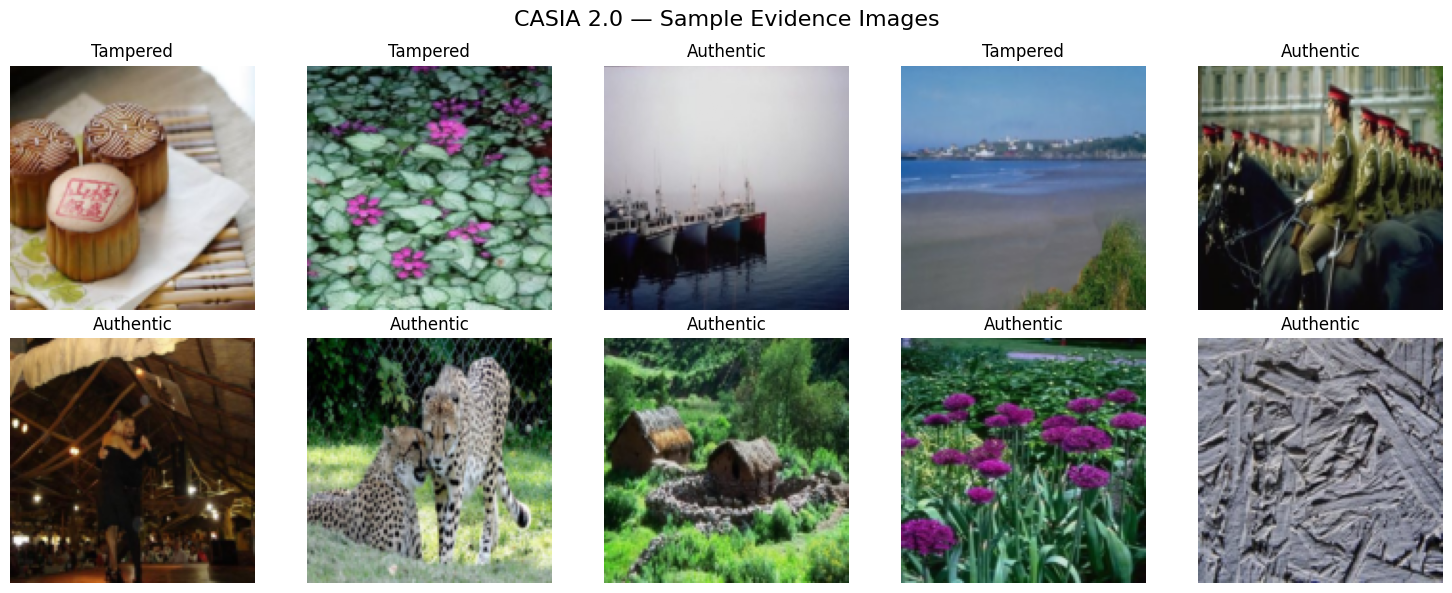

✅ Image visualization completed.
Authentic label = 0
Tampered label  = 1


In [9]:


import matplotlib.pyplot as plt

# Get one batch from the training loader
images, labels = next(iter(train_loader))

# Create figure
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    # Convert tensor: C,H,W → H,W,C
    image = images[i].permute(1, 2, 0).numpy()

    ax.imshow(image)

    if labels[i].item() == 0:
        ax.set_title("Authentic")
    else:
        ax.set_title("Tampered")

    ax.axis("off")

plt.suptitle(
    "CASIA 2.0 — Sample Evidence Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("✅ Image visualization completed.")
print("Authentic label = 0")
print("Tampered label  = 1")

# CELL 7 — IMPROVED TRANSFORMER FORENSIC AUTOENCODER

In [10]:


class TransformerForensicAutoencoder(nn.Module):

    def __init__(
        self,
        image_size=128,
        patch_size=16,
        in_channels=3,
        embed_dim=256,
        num_heads=8,
        num_encoder_layers=4,
        num_decoder_layers=2,
        dropout=0.1
    ):
        super().__init__()

        # ----------------------------------------------------
        # Model configuration
        # ----------------------------------------------------

        self.image_size = image_size
        self.patch_size = patch_size
        self.in_channels = in_channels
        self.embed_dim = embed_dim

        # Number of patches
        self.num_patches = (
            image_size // patch_size
        ) ** 2

        # ----------------------------------------------------
        # 1. Patch Embedding
        # ----------------------------------------------------

        self.patch_embed = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # ----------------------------------------------------
        # 2. Learnable positional embedding
        # ----------------------------------------------------

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.num_patches,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # 3. Transformer Encoder
        # ----------------------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers
        )

        # ----------------------------------------------------
        # 4. Latent normalization
        # ----------------------------------------------------

        self.latent_norm = nn.LayerNorm(embed_dim)

        # ----------------------------------------------------
        # 5. Transformer Decoder
        # ----------------------------------------------------

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_decoder_layers
        )

        # ----------------------------------------------------
        # 6. Reconstruction head
        # ----------------------------------------------------

        self.reconstruction_head = nn.Linear(
            embed_dim,
            patch_size * patch_size * in_channels
        )

        # ----------------------------------------------------
        # Initialize positional embeddings
        # ----------------------------------------------------

        nn.init.trunc_normal_(
            self.pos_embedding,
            std=0.02
        )

    # ========================================================
    # Forward pass
    # ========================================================

    def forward(self, x, return_attention=False):

        B = x.size(0)

        # ----------------------------------------------------
        # Patch embedding
        # ----------------------------------------------------

        patches = self.patch_embed(x)

        # Shape:
        # B × embed_dim × 8 × 8

        patches = patches.flatten(2)

        # Shape:
        # B × embed_dim × 64

        patches = patches.transpose(1, 2)

        # Shape:
        # B × 64 × embed_dim

        # ----------------------------------------------------
        # Add positional information
        # ----------------------------------------------------

        tokens = patches + self.pos_embedding

        # ----------------------------------------------------
        # Transformer encoding
        # ----------------------------------------------------

        encoded = self.encoder(tokens)

        # ----------------------------------------------------
        # Latent representation
        # ----------------------------------------------------

        latent = self.latent_norm(encoded)

        # ----------------------------------------------------
        # Transformer decoding
        # ----------------------------------------------------

        decoded = self.decoder(
            tgt=latent,
            memory=encoded
        )

        # ----------------------------------------------------
        # Reconstruct image patches
        # ----------------------------------------------------

        reconstructed_patches = self.reconstruction_head(
            decoded
        )

        # Shape:
        # B × 64 × (16 × 16 × 3)

        # ----------------------------------------------------
        # Convert patches back to image
        # ----------------------------------------------------

        reconstructed_patches = reconstructed_patches.view(
            B,
            self.image_size // self.patch_size,
            self.image_size // self.patch_size,
            self.patch_size,
            self.patch_size,
            self.in_channels
        )

        reconstructed_patches = reconstructed_patches.permute(
            0, 5, 1, 3, 2, 4
        )

        reconstructed = reconstructed_patches.contiguous().view(
            B,
            self.in_channels,
            self.image_size,
            self.image_size
        )

        # Keep output in valid image range
        reconstructed = torch.sigmoid(reconstructed)

        # ----------------------------------------------------
        # Global latent representation
        # ----------------------------------------------------

        global_latent = latent.mean(dim=1)

        if return_attention:
            return reconstructed, global_latent, latent

        return reconstructed


# ============================================================
# Create model
# ============================================================

model = TransformerForensicAutoencoder(
    image_size=IMAGE_SIZE,
    patch_size=16,
    in_channels=3,
    embed_dim=256,
    num_heads=8,
    num_encoder_layers=4,
    num_decoder_layers=2,
    dropout=0.1
).to(DEVICE)


# ============================================================
# Parameter count
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("IMPROVED TRANSFORMER FORENSIC AUTOENCODER")
print("=" * 60)

print(f"Image size          : {IMAGE_SIZE} × {IMAGE_SIZE}")
print(f"Patch size          : 16 × 16")
print(f"Number of patches   : {model.num_patches}")
print(f"Embedding dimension : 256")
print(f"Attention heads     : 8")
print(f"Encoder layers      : 4")
print(f"Decoder layers      : 2")
print(f"Dropout             : 0.1")

print("\nTotal parameters    :", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("\nDevice              :", DEVICE)

IMPROVED TRANSFORMER FORENSIC AUTOENCODER
Image size          : 128 × 128
Patch size          : 16 × 16
Number of patches   : 64
Embedding dimension : 256
Attention heads     : 8
Encoder layers      : 4
Decoder layers      : 2
Dropout             : 0.1

Total parameters    : 5,677,056
Trainable parameters: 5,677,056

Device              : cuda


/tmp/ipykernel_1309/251548920.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


# CELL 8 — TRANSFORMER FORWARD-PASS SMOKE TEST


In [11]:


model.eval()

# Get one batch
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(DEVICE)

# Forward pass
with torch.no_grad():

    reconstructed, global_latent, latent_tokens = model(
        images,
        return_attention=True
    )

# ------------------------------------------------------------
# Display shapes
# ------------------------------------------------------------

print("=" * 60)
print("TRANSFORMER SMOKE TEST")
print("=" * 60)

print("Input image shape       :", images.shape)
print("Latent token shape      :", latent_tokens.shape)
print("Global latent shape     :", global_latent.shape)
print("Reconstructed shape     :", reconstructed.shape)

# ------------------------------------------------------------
# Check numerical validity
# ------------------------------------------------------------

print("\nInput range:")
print(
    f"Min = {images.min().item():.4f}, "
    f"Max = {images.max().item():.4f}"
)

print("\nReconstruction range:")
print(
    f"Min = {reconstructed.min().item():.4f}, "
    f"Max = {reconstructed.max().item():.4f}"
)

# ------------------------------------------------------------
# Calculate initial reconstruction error
# ------------------------------------------------------------

batch_mse = F.mse_loss(
    reconstructed,
    images
)

print("\nInitial reconstruction MSE :",
      f"{batch_mse.item():.6f}")

# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

assert images.shape == reconstructed.shape
assert latent_tokens.shape[1] == model.num_patches
assert global_latent.shape[1] == model.embed_dim

print("\n✅ Input and output dimensions match.")
print("✅ Latent representation generated.")
print("✅ Transformer forward pass successful.")
print("✅ Step 8 completed successfully.")

TRANSFORMER SMOKE TEST
Input image shape       : torch.Size([32, 3, 128, 128])
Latent token shape      : torch.Size([32, 64, 256])
Global latent shape     : torch.Size([32, 256])
Reconstructed shape     : torch.Size([32, 3, 128, 128])

Input range:
Min = 0.0000, Max = 1.0000

Reconstruction range:
Min = 0.0247, Max = 0.9673

Initial reconstruction MSE : 0.132110

✅ Input and output dimensions match.
✅ Latent representation generated.
✅ Transformer forward pass successful.
✅ Step 8 completed successfully.


CELL 9 — TRAINING CONFIGURATION

In [12]:

# ------------------------------------------------------------
# Training hyperparameters
# ------------------------------------------------------------

EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

# ------------------------------------------------------------
# Reconstruction loss
# ------------------------------------------------------------

criterion = nn.MSELoss()

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# ------------------------------------------------------------
# Mixed precision for Tesla T4
# ------------------------------------------------------------

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

CHECKPOINT_DIR = Path("/content/transformer_checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT = (
    CHECKPOINT_DIR /
    "best_transformer_forensic.pth"
)

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 60)
print("TRANSFORMER TRAINING CONFIGURATION")
print("=" * 60)

print(f"Epochs          : {EPOCHS}")
print(f"Learning rate    : {LEARNING_RATE}")
print(f"Weight decay     : {WEIGHT_DECAY}")
print(f"Loss function    : MSE")
print(f"Optimizer        : AdamW")
print(f"Scheduler        : ReduceLROnPlateau")
print(f"Mixed precision  : {torch.cuda.is_available()}")

print("\nCheckpoint:")
print(BEST_CHECKPOINT)

print("\n✅ Training configuration ready.")

TRANSFORMER TRAINING CONFIGURATION
Epochs          : 50
Learning rate    : 0.0001
Weight decay     : 1e-05
Loss function    : MSE
Optimizer        : AdamW
Scheduler        : ReduceLROnPlateau
Mixed precision  : True

Checkpoint:
/content/transformer_checkpoints/best_transformer_forensic.pth

✅ Training configuration ready.


# CELL 10 — TRANSFORMER TRAINING

In [13]:


import time

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0

print("=" * 60)
print("TRANSFORMER TRAINING STARTED")
print("=" * 60)

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    running_train_loss = 0.0

    for images, _ in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            reconstructed = model(images)

            loss = criterion(
                reconstructed,
                images
            )

        # Backpropagation
        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss /
        len(train_loader)
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                reconstructed = model(images)

                loss = criterion(
                    reconstructed,
                    images
                )

            running_val_loss += loss.item()

    val_loss = (
        running_val_loss /
        len(val_loader)
    )

    # Store losses
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Learning-rate scheduler
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "train_loss": train_loss,
                "config": {
                    "image_size": IMAGE_SIZE,
                    "patch_size": 16,
                    "embed_dim": 256,
                    "num_heads": 8,
                    "encoder_layers": 4,
                    "decoder_layers": 2
                }
            },
            BEST_CHECKPOINT
        )

        marker = " ★ BEST"

    else:
        marker = ""

    # ========================================================
    # PRINT PROGRESS
    # ========================================================

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train MSE: {train_loss:.6f} | "
        f"Val MSE: {val_loss:.6f} | "
        f"LR: {current_lr:.2e}"
        f"{marker}"
    )


# ============================================================
# TRAINING TIME
# ============================================================

training_time = time.time() - start_time

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print(f"Best epoch       : {best_epoch}")
print(f"Best val MSE     : {best_val_loss:.6f}")
print(f"Training time    : {training_time / 60:.2f} minutes")
print(f"Best checkpoint  : {BEST_CHECKPOINT}")

print("\n✅ Transformer training completed.")

TRANSFORMER TRAINING STARTED
Epoch [01/50] | Train MSE: 0.029232 | Val MSE: 0.013258 | LR: 1.00e-04 ★ BEST
Epoch [02/50] | Train MSE: 0.012357 | Val MSE: 0.009200 | LR: 1.00e-04 ★ BEST
Epoch [03/50] | Train MSE: 0.009210 | Val MSE: 0.007392 | LR: 1.00e-04 ★ BEST
Epoch [04/50] | Train MSE: 0.007666 | Val MSE: 0.006599 | LR: 1.00e-04 ★ BEST
Epoch [05/50] | Train MSE: 0.006646 | Val MSE: 0.005486 | LR: 1.00e-04 ★ BEST
Epoch [06/50] | Train MSE: 0.005860 | Val MSE: 0.004832 | LR: 1.00e-04 ★ BEST
Epoch [07/50] | Train MSE: 0.005262 | Val MSE: 0.004361 | LR: 1.00e-04 ★ BEST
Epoch [08/50] | Train MSE: 0.004803 | Val MSE: 0.004016 | LR: 1.00e-04 ★ BEST
Epoch [09/50] | Train MSE: 0.004477 | Val MSE: 0.003686 | LR: 1.00e-04 ★ BEST
Epoch [10/50] | Train MSE: 0.004155 | Val MSE: 0.003437 | LR: 1.00e-04 ★ BEST
Epoch [11/50] | Train MSE: 0.003882 | Val MSE: 0.003240 | LR: 1.00e-04 ★ BEST
Epoch [12/50] | Train MSE: 0.003655 | Val MSE: 0.002987 | LR: 1.00e-04 ★ BEST
Epoch [13/50] | Train MSE: 0.003432

# CELL 11 — TRAINING & VALIDATION LOSS CURVES

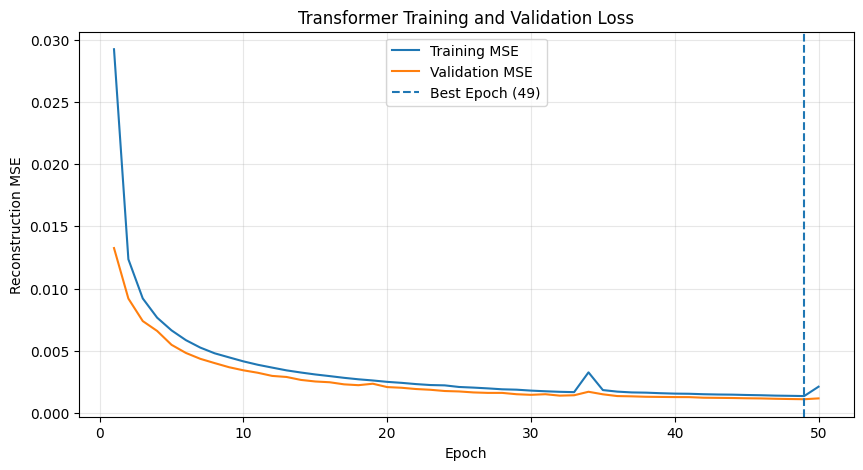

Best epoch   : 49
Best Val MSE : 0.001115

✅ Loss curves generated.


In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training MSE"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation MSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Transformer Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print("Best epoch   :", best_epoch)
print("Best Val MSE :", f"{best_val_loss:.6f}")

print("\n✅ Loss curves generated.")

# CELL 12 — LOAD BEST TRANSFORMER CHECKPOINT

In [15]:
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()

print("=" * 60)
print("BEST TRANSFORMER CHECKPOINT LOADED")
print("=" * 60)

print("Checkpoint path :", BEST_CHECKPOINT)
print("Best epoch      :", checkpoint["epoch"])
print("Train MSE       :", f"{checkpoint['train_loss']:.6f}")
print("Validation MSE  :", f"{checkpoint['val_loss']:.6f}")
print("Model device    :", DEVICE)

print("\n✅ Best model loaded successfully.")

BEST TRANSFORMER CHECKPOINT LOADED
Checkpoint path : /content/transformer_checkpoints/best_transformer_forensic.pth
Best epoch      : 49
Train MSE       : 0.001368
Validation MSE  : 0.001115
Model device    : cuda

✅ Best model loaded successfully.


# CELL 13 — TEST SET RECONSTRUCTION & FORENSIC METRICS


In [16]:


from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

model.eval()

test_results = []

print("=" * 60)
print("TEST SET FORENSIC EVALUATION")
print("=" * 60)

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        # Transformer reconstruction
        reconstructed = model(images)

        # Move to CPU
        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()
        labels_np = labels.numpy()

        # -----------------------------------------------
        # Calculate image-level metrics
        # -----------------------------------------------

        for i in range(len(images)):

            original = np.transpose(
                original_np[i],
                (1, 2, 0)
            )

            recon = np.transpose(
                reconstructed_np[i],
                (1, 2, 0)
            )

            # MSE
            mse_value = np.mean(
                (original - recon) ** 2
            )

            # PSNR
            psnr_value = psnr(
                original,
                recon,
                data_range=1.0
            )

            # SSIM
            ssim_value = ssim(
                original,
                recon,
                data_range=1.0,
                channel_axis=2
            )

            test_results.append({
                "path": test_df.iloc[
                    batch_idx * BATCH_SIZE + i
                ]["path"],
                "label": int(labels_np[i]),
                "class": (
                    "authentic"
                    if labels_np[i] == 0
                    else "tampered"
                ),
                "mse": mse_value,
                "psnr": psnr_value,
                "ssim": ssim_value
            })


# Convert to DataFrame
test_results_df = pd.DataFrame(test_results)

# ------------------------------------------------------------
# Overall statistics
# ------------------------------------------------------------

print("\nTotal test images:", len(test_results_df))

print("\nOverall metrics:")
print(
    f"Mean MSE  : {test_results_df['mse'].mean():.6f}"
)

print(
    f"Mean PSNR : {test_results_df['psnr'].mean():.4f} dB"
)

print(
    f"Mean SSIM : {test_results_df['ssim'].mean():.4f}"
)

# ------------------------------------------------------------
# Authentic statistics
# ------------------------------------------------------------

auth_results = test_results_df[
    test_results_df["label"] == 0
]

tampered_results = test_results_df[
    test_results_df["label"] == 1
]

print("\n" + "=" * 60)
print("AUTHENTIC vs TAMPERED")
print("=" * 60)

print("\nAuthentic:")
print(
    f"Count     : {len(auth_results)}"
)
print(
    f"Mean MSE  : {auth_results['mse'].mean():.6f}"
)
print(
    f"Mean PSNR : {auth_results['psnr'].mean():.4f} dB"
)
print(
    f"Mean SSIM : {auth_results['ssim'].mean():.4f}"
)

print("\nTampered:")
print(
    f"Count     : {len(tampered_results)}"
)
print(
    f"Mean MSE  : {tampered_results['mse'].mean():.6f}"
)
print(
    f"Mean PSNR : {tampered_results['psnr'].mean():.4f} dB"
)
print(
    f"Mean SSIM : {tampered_results['ssim'].mean():.4f}"
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

RESULTS_FILE = "/content/transformer_test_results.csv"

test_results_df.to_csv(
    RESULTS_FILE,
    index=False
)

print("\nResults saved to:")
print(RESULTS_FILE)

print("\n✅ Step 13 completed successfully.")

TEST SET FORENSIC EVALUATION

Total test images: 2523

Overall metrics:
Mean MSE  : 0.001101
Mean PSNR : 30.3878 dB
Mean SSIM : 0.9141

AUTHENTIC vs TAMPERED

Authentic:
Count     : 1498
Mean MSE  : 0.001043
Mean PSNR : 30.5786 dB
Mean SSIM : 0.9164

Tampered:
Count     : 1025
Mean MSE  : 0.001186
Mean PSNR : 30.1089 dB
Mean SSIM : 0.9108

Results saved to:
/content/transformer_test_results.csv

✅ Step 13 completed successfully.


# CELL 14 — AUTHENTIC VALIDATION THRESHOLD


In [17]:


model.eval()

authentic_val_errors = []

print("=" * 60)
print("AUTHENTIC VALIDATION THRESHOLD")
print("=" * 60)

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        reconstructed = model(images)

        # Per-image reconstruction MSE
        mse_per_image = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        # Keep only authentic images
        authentic_mask = labels == 0

        authentic_errors = mse_per_image[
            authentic_mask.to(DEVICE)
        ]

        authentic_val_errors.extend(
            authentic_errors.cpu().numpy().tolist()
        )


# Convert to NumPy
authentic_val_errors = np.array(
    authentic_val_errors
)

# ------------------------------------------------------------
# Calculate threshold
# ------------------------------------------------------------

THRESHOLD_PERCENTILE = 95

AUTHENTIC_THRESHOLD = np.percentile(
    authentic_val_errors,
    THRESHOLD_PERCENTILE
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

print(f"Authentic validation images : {len(authentic_val_errors)}")

print(
    f"Mean MSE    : "
    f"{authentic_val_errors.mean():.6f}"
)

print(
    f"Median MSE  : "
    f"{np.median(authentic_val_errors):.6f}"
)

print(
    f"Std MSE     : "
    f"{authentic_val_errors.std():.6f}"
)

print(
    f"Minimum MSE : "
    f"{authentic_val_errors.min():.6f}"
)

print(
    f"Maximum MSE : "
    f"{authentic_val_errors.max():.6f}"
)

print("\n" + "=" * 60)

print(
    f"{THRESHOLD_PERCENTILE}th percentile threshold : "
    f"{AUTHENTIC_THRESHOLD:.6f}"
)

print("=" * 60)

print(
    "\nInterpretation:"
)

print(
    "Images with reconstruction error above this "
    "threshold will be flagged as Potential Anomaly "
    "for further forensic examination."
)

print(
    "\n⚠️ This threshold is an AI-assisted screening "
    "indicator, not proof of image manipulation."
)

print("\n✅ Authentic threshold established.")

AUTHENTIC VALIDATION THRESHOLD
Authentic validation images : 1199
Mean MSE    : 0.001035
Median MSE  : 0.000886
Std MSE     : 0.000710
Minimum MSE : 0.000049
Maximum MSE : 0.005944

95th percentile threshold : 0.002253

Interpretation:
Images with reconstruction error above this threshold will be flagged as Potential Anomaly for further forensic examination.

⚠️ This threshold is an AI-assisted screening indicator, not proof of image manipulation.

✅ Authentic threshold established.


# CELL 15 — FORENSIC RECONSTRUCTION VISUALIZATION


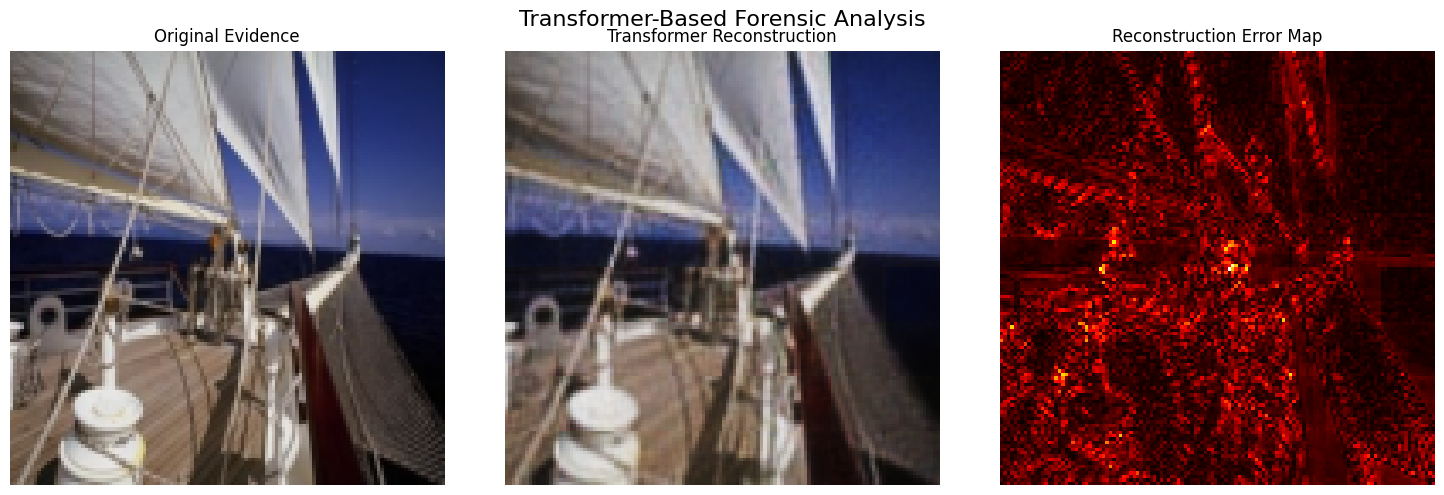

FORENSIC IMAGE ANALYSIS
Evidence file : Au_art_30358.jpg
Dataset label : Authentic
Reconstruction MSE : 0.001093
Threshold           : 0.002253
AI screening status  : NORMAL

⚠️ The status is an AI-assisted screening result.
It is not conclusive proof of manipulation.

✅ Step 15 completed successfully.


In [18]:

model.eval()

# ------------------------------------------------------------
# 1. Select one test image
# ------------------------------------------------------------

sample_index = 0

sample_path = test_df.iloc[sample_index]["path"]
sample_label = int(test_df.iloc[sample_index]["label"])

# ------------------------------------------------------------
# 2. Load and preprocess image
# ------------------------------------------------------------

sample_image = Image.open(sample_path).convert("RGB")

sample_tensor = transform(sample_image).unsqueeze(0).to(DEVICE)

# ------------------------------------------------------------
# 3. Transformer reconstruction
# ------------------------------------------------------------

with torch.no_grad():

    reconstructed_tensor = model(sample_tensor)

# ------------------------------------------------------------
# 4. Convert tensors to NumPy images
# ------------------------------------------------------------

original = sample_tensor.squeeze(0).cpu().numpy()
reconstructed = reconstructed_tensor.squeeze(0).cpu().numpy()

# C,H,W → H,W,C
original = np.transpose(original, (1, 2, 0))
reconstructed = np.transpose(reconstructed, (1, 2, 0))

# ------------------------------------------------------------
# 5. Calculate pixel-level error map
# ------------------------------------------------------------

error_map = np.mean(
    np.abs(original - reconstructed),
    axis=2
)

# Image-level MSE
mse_value = np.mean(
    (original - reconstructed) ** 2
)

# ------------------------------------------------------------
# 6. Classification using authentic threshold
# ------------------------------------------------------------

if mse_value > AUTHENTIC_THRESHOLD:
    status = "POTENTIAL ANOMALY"
else:
    status = "NORMAL"

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(original)
axes[0].set_title("Original Evidence")
axes[0].axis("off")

axes[1].imshow(reconstructed)
axes[1].set_title("Transformer Reconstruction")
axes[1].axis("off")

axes[2].imshow(error_map, cmap="hot")
axes[2].set_title("Reconstruction Error Map")
axes[2].axis("off")

plt.suptitle(
    "Transformer-Based Forensic Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Print analysis information
# ------------------------------------------------------------

print("=" * 60)
print("FORENSIC IMAGE ANALYSIS")
print("=" * 60)

print("Evidence file :", Path(sample_path).name)

print(
    "Dataset label :",
    "Authentic" if sample_label == 0 else "Tampered"
)

print(f"Reconstruction MSE : {mse_value:.6f}")

print(
    f"Threshold           : "
    f"{AUTHENTIC_THRESHOLD:.6f}"
)

print("AI screening status  :", status)

print("\n⚠️ The status is an AI-assisted screening result.")
print("It is not conclusive proof of manipulation.")

print("\n✅ Step 15 completed successfully.")

# CELL 16 — TEST A TAMPERED EVIDENCE IMAGE


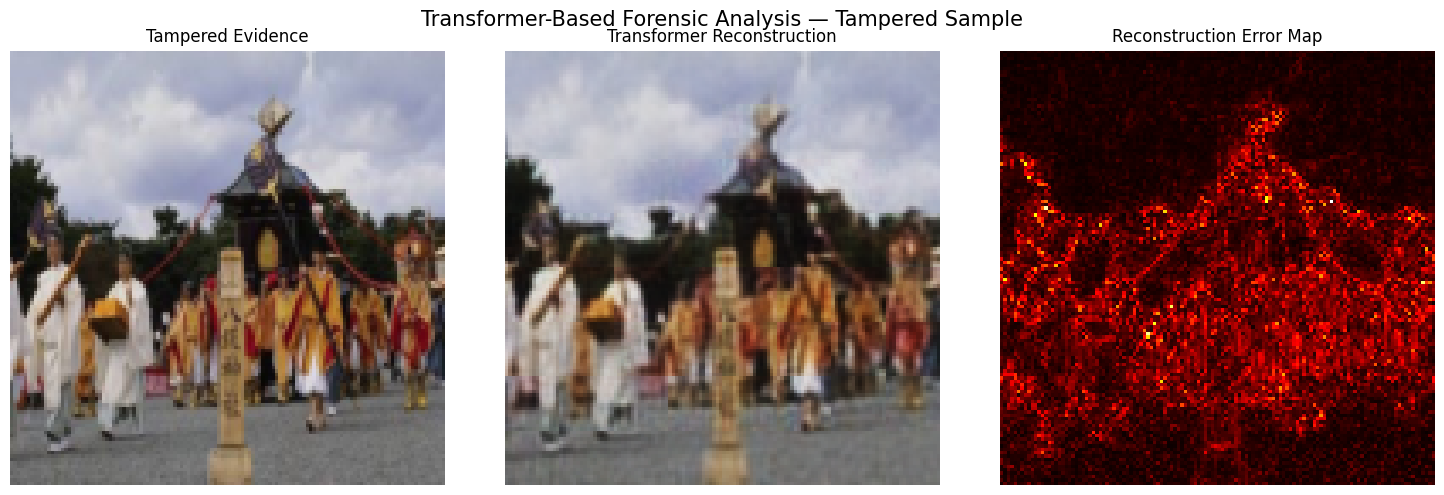

TAMPERED SAMPLE ANALYSIS
Evidence file       : Tp_D_NNN_S_N_sec00027_sec00026_10771.jpg
Dataset label       : Tampered
Reconstruction MSE  : 0.001051
Threshold           : 0.002253
AI screening status : NORMAL

⚠️ This is an AI-assisted screening result.
It should not be treated as conclusive proof of manipulation.

✅ Step 16 completed successfully.


In [19]:
model.eval()

# Find the first tampered image from the test set
tampered_sample = test_df[
    test_df["label"] == 1
].iloc[0]

sample_path = tampered_sample["path"]

# Load image
sample_image = Image.open(sample_path).convert("RGB")

# Preprocess
sample_tensor = transform(
    sample_image
).unsqueeze(0).to(DEVICE)

# Reconstruction
with torch.no_grad():
    reconstructed_tensor = model(sample_tensor)

# Convert to NumPy
original = sample_tensor.squeeze(0).cpu().numpy()
reconstructed = reconstructed_tensor.squeeze(0).cpu().numpy()

original = np.transpose(original, (1, 2, 0))
reconstructed = np.transpose(reconstructed, (1, 2, 0))

# Error map
error_map = np.mean(
    np.abs(original - reconstructed),
    axis=2
)

# MSE
mse_value = np.mean(
    (original - reconstructed) ** 2
)

# Status
status = (
    "POTENTIAL ANOMALY"
    if mse_value > AUTHENTIC_THRESHOLD
    else "NORMAL"
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(original)
axes[0].set_title("Tampered Evidence")
axes[0].axis("off")

axes[1].imshow(reconstructed)
axes[1].set_title("Transformer Reconstruction")
axes[1].axis("off")

axes[2].imshow(error_map, cmap="hot")
axes[2].set_title("Reconstruction Error Map")
axes[2].axis("off")

plt.suptitle(
    "Transformer-Based Forensic Analysis — Tampered Sample",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 60)
print("TAMPERED SAMPLE ANALYSIS")
print("=" * 60)

print("Evidence file       :", Path(sample_path).name)
print("Dataset label       : Tampered")
print(f"Reconstruction MSE  : {mse_value:.6f}")
print(f"Threshold           : {AUTHENTIC_THRESHOLD:.6f}")
print("AI screening status :", status)

print("\n⚠️ This is an AI-assisted screening result.")
print("It should not be treated as conclusive proof of manipulation.")

print("\n✅ Step 16 completed successfully.")

# CELL 17 — TRANSFORMER ATTENTION MAP EXTRACTION

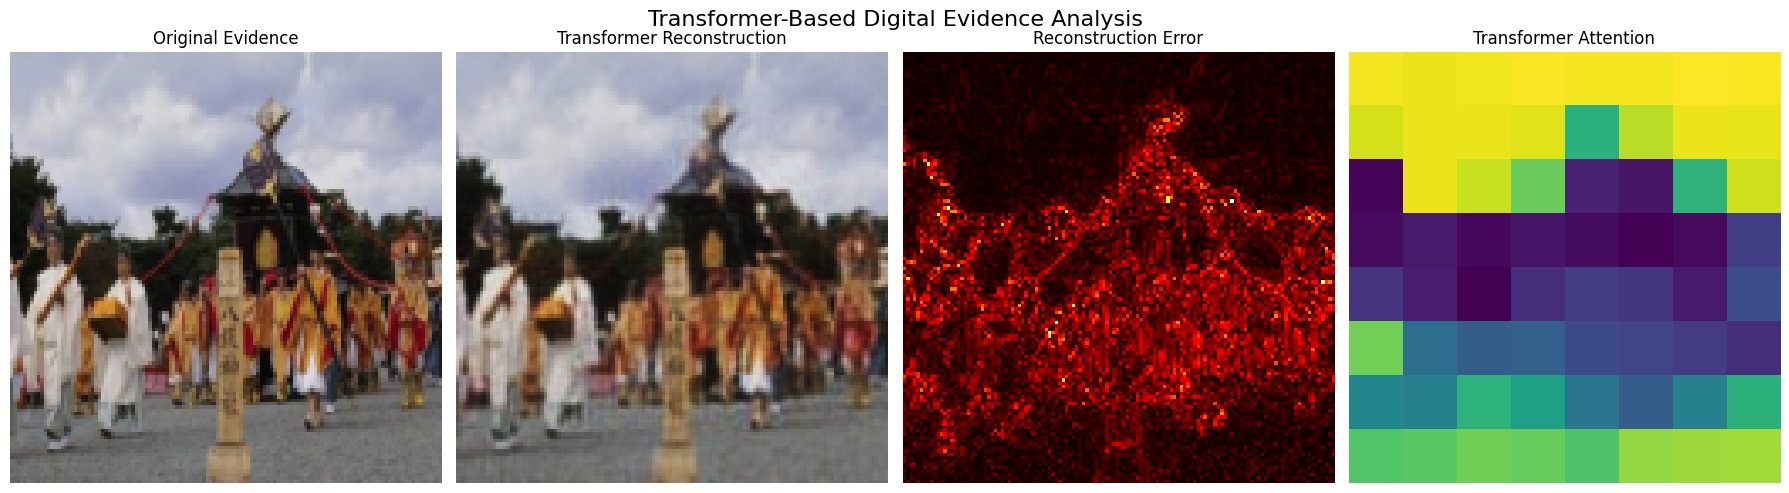

TRANSFORMER ATTENTION ANALYSIS
Evidence file       : Tp_D_NNN_S_N_sec00027_sec00026_10771.jpg
Latent dimension    : 256
Attention map size  : (8, 8)
Reconstruction MSE  : 0.001050
Threshold           : 0.002253
AI screening status : NORMAL

Attention map range:
Minimum : 0.0000
Maximum : 1.0000

⚠️ Attention highlights regions receiving stronger
Transformer attention. It is not direct proof of tampering.

✅ Step 17 completed successfully.


In [20]:

model.eval()


def extract_transformer_attention(model, image_tensor):
    """
    Extract attention information from all Transformer
    encoder layers.

    Returns:
        reconstructed : reconstructed image
        global_latent : 256-D latent representation
        attention_map : 8x8 spatial attention map
    """

    with torch.no_grad():

        # ----------------------------------------------------
        # 1. Patch embedding
        # ----------------------------------------------------

        patches = model.patch_embed(image_tensor)

        # B × 256 × 8 × 8

        patches = patches.flatten(2)

        # B × 256 × 64

        patches = patches.transpose(1, 2)

        # B × 64 × 256

        # ----------------------------------------------------
        # 2. Positional embedding
        # ----------------------------------------------------

        tokens = patches + model.pos_embedding

        attention_maps = []

        # ----------------------------------------------------
        # 3. Manually pass through encoder layers
        #    so we can capture attention weights
        # ----------------------------------------------------

        for layer in model.encoder.layers:

            # ----------------------------------------------
            # Pre-normalization
            # ----------------------------------------------

            normalized_tokens = layer.norm1(tokens)

            # ----------------------------------------------
            # Multi-head self-attention
            # ----------------------------------------------

            attention_output, attention_weights = layer.self_attn(
                normalized_tokens,
                normalized_tokens,
                normalized_tokens,
                need_weights=True,
                average_attn_weights=False
            )

            # Save attention
            # Shape:
            # B × Heads × 64 × 64

            attention_maps.append(
                attention_weights.detach()
            )

            # ----------------------------------------------
            # Residual connection
            # ----------------------------------------------

            tokens = tokens + layer.dropout1(
                attention_output
            )

            # ----------------------------------------------
            # Feed-forward network
            # ----------------------------------------------

            normalized_tokens = layer.norm2(tokens)

            ff_output = layer.linear2(
                layer.dropout(
                    layer.activation(
                        layer.linear1(normalized_tokens)
                    )
                )
            )

            tokens = tokens + layer.dropout2(
                ff_output
            )

        # ----------------------------------------------------
        # 4. Latent normalization
        # ----------------------------------------------------

        latent = model.latent_norm(tokens)

        # ----------------------------------------------------
        # 5. Decoder reconstruction
        # ----------------------------------------------------

        decoded = model.decoder(
            tgt=latent,
            memory=tokens
        )

        reconstructed_patches = model.reconstruction_head(
            decoded
        )

        B = image_tensor.size(0)

        reconstructed_patches = reconstructed_patches.view(
            B,
            model.image_size // model.patch_size,
            model.image_size // model.patch_size,
            model.patch_size,
            model.patch_size,
            model.in_channels
        )

        reconstructed_patches = reconstructed_patches.permute(
            0, 5, 1, 3, 2, 4
        )

        reconstructed = reconstructed_patches.contiguous().view(
            B,
            model.in_channels,
            model.image_size,
            model.image_size
        )

        reconstructed = torch.sigmoid(
            reconstructed
        )

        # ----------------------------------------------------
        # 6. Global latent representation
        # ----------------------------------------------------

        global_latent = latent.mean(dim=1)

        # ----------------------------------------------------
        # 7. Combine attention from all encoder layers
        # ----------------------------------------------------

        # Stack:
        # Layers × B × Heads × 64 × 64

        attention_stack = torch.stack(
            attention_maps,
            dim=0
        )

        # Average over layers and heads
        # Result:
        # B × 64 × 64

        attention_average = attention_stack.mean(
            dim=(0, 2)
        )

        # Average attention received by each patch
        # across all query patches

        patch_attention = attention_average.mean(
            dim=1
        )

        # B × 64
        # Convert to spatial 8 × 8

        attention_map = patch_attention.view(
            B,
            model.image_size // model.patch_size,
            model.image_size // model.patch_size
        )

        # Normalize each image from 0 to 1

        min_values = attention_map.amin(
            dim=(1, 2),
            keepdim=True
        )

        max_values = attention_map.amax(
            dim=(1, 2),
            keepdim=True
        )

        attention_map = (
            attention_map - min_values
        ) / (
            max_values - min_values + 1e-8
        )

    return (
        reconstructed,
        global_latent,
        attention_map
    )


# ============================================================
# Run attention extraction on the tampered sample
# ============================================================

sample_path = tampered_sample["path"]

sample_image = Image.open(
    sample_path
).convert("RGB")

sample_tensor = transform(
    sample_image
).unsqueeze(0).to(DEVICE)

reconstructed_tensor, global_latent, attention_map = (
    extract_transformer_attention(
        model,
        sample_tensor
    )
)

# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

original = sample_tensor.squeeze(0).cpu().numpy()
reconstructed = reconstructed_tensor.squeeze(0).cpu().numpy()
attention = attention_map.squeeze(0).cpu().numpy()

original = np.transpose(
    original,
    (1, 2, 0)
)

reconstructed = np.transpose(
    reconstructed,
    (1, 2, 0)
)

# Reconstruction error
error_map = np.mean(
    np.abs(original - reconstructed),
    axis=2
)

mse_value = np.mean(
    (original - reconstructed) ** 2
)

status = (
    "POTENTIAL ANOMALY"
    if mse_value > AUTHENTIC_THRESHOLD
    else "NORMAL"
)

# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5)
)

axes[0].imshow(original)
axes[0].set_title("Original Evidence")
axes[0].axis("off")

axes[1].imshow(reconstructed)
axes[1].set_title("Transformer Reconstruction")
axes[1].axis("off")

axes[2].imshow(
    error_map,
    cmap="hot"
)
axes[2].set_title("Reconstruction Error")
axes[2].axis("off")

axes[3].imshow(
    attention,
    cmap="viridis",
    interpolation="nearest"
)
axes[3].set_title("Transformer Attention")
axes[3].axis("off")

plt.suptitle(
    "Transformer-Based Digital Evidence Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ============================================================
# RESULTS
# ============================================================

print("=" * 60)
print("TRANSFORMER ATTENTION ANALYSIS")
print("=" * 60)

print("Evidence file       :", Path(sample_path).name)
print("Latent dimension    :", global_latent.shape[1])
print("Attention map size  :", attention.shape)
print(f"Reconstruction MSE  : {mse_value:.6f}")
print(f"Threshold           : {AUTHENTIC_THRESHOLD:.6f}")
print("AI screening status :", status)

print("\nAttention map range:")
print(f"Minimum : {attention.min():.4f}")
print(f"Maximum : {attention.max():.4f}")

print("\n⚠️ Attention highlights regions receiving stronger")
print("Transformer attention. It is not direct proof of tampering.")

print("\n✅ Step 17 completed successfully.")

# CELL 18 — REAL EVIDENCE IMAGE UPLOAD & ANALYSIS


DIGITAL EVIDENCE IMAGE UPLOAD


Saving evidence.jpeg to evidence.jpeg

✅ Evidence image uploaded:
Filename: evidence.jpeg

Evidence SHA-256:
76067db4d8f03ebc80876811289ad6d64ae794c9f152146fc96bf07ea3f2d883

EVIDENCE INFORMATION
Filename       : evidence.jpeg
Original size  : 900 × 1600
File size      : 140.74 KB
Analysis time  : 2026-09-16 10:58:48


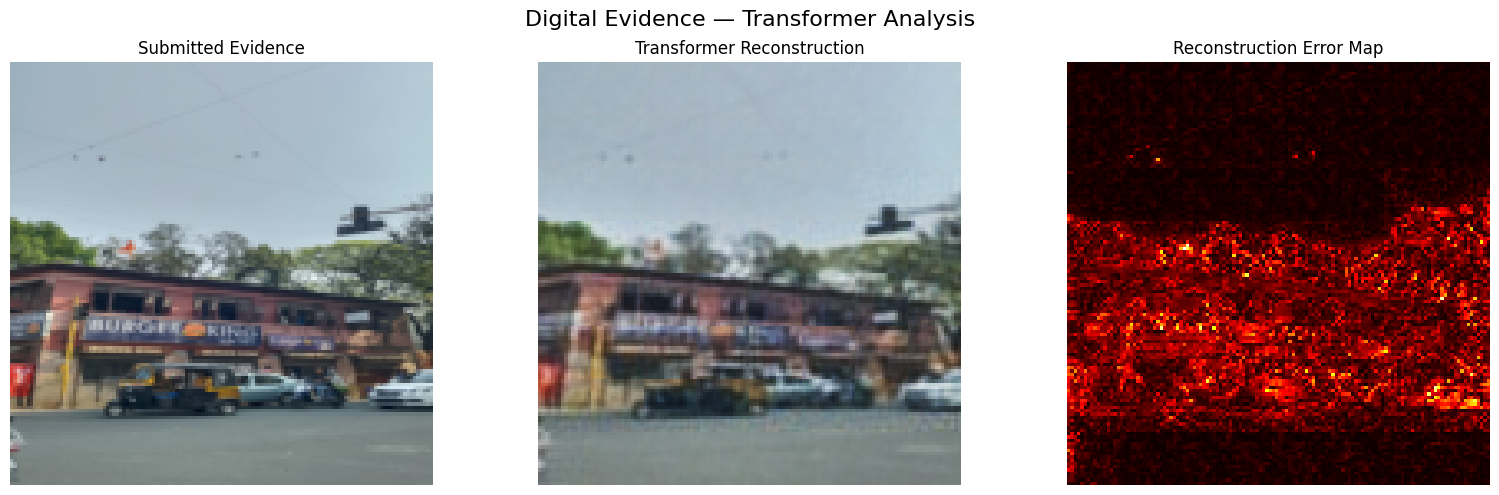


TRANSFORMER EVIDENCE ANALYSIS RESULT
Evidence file       : evidence.jpeg
SHA-256             : 76067db4d8f03ebc80876811289ad6d64ae794c9f152146fc96bf07ea3f2d883
Reconstruction MSE  : 0.000886
PSNR                : 30.5277 dB
SSIM                : 0.9420
Authentic threshold : 0.002253
AI screening status : NORMAL

⚠️ Important:
The screening status is an AI-assisted forensic indicator and is not conclusive proof of authenticity or manipulation.

✅ Step 18 completed successfully.


In [21]:
from google.colab import files
import hashlib
from datetime import datetime

# ------------------------------------------------------------
# 1. Upload evidence image
# ------------------------------------------------------------

print("=" * 60)
print("DIGITAL EVIDENCE IMAGE UPLOAD")
print("=" * 60)

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No evidence image was uploaded.")

# Get uploaded filename
evidence_filename = list(uploaded.keys())[0]

# Full path
evidence_path = Path("/content") / evidence_filename

print("\n✅ Evidence image uploaded:")
print("Filename:", evidence_filename)


# ------------------------------------------------------------
# 2. Calculate SHA-256 hash
# ------------------------------------------------------------

sha256_hash = hashlib.sha256()

with open(evidence_path, "rb") as f:

    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        sha256_hash.update(chunk)

evidence_hash = sha256_hash.hexdigest()

print("\nEvidence SHA-256:")
print(evidence_hash)


# ------------------------------------------------------------
# 3. Read image information
# ------------------------------------------------------------

original_evidence = Image.open(
    evidence_path
).convert("RGB")

original_width, original_height = original_evidence.size

file_size_kb = evidence_path.stat().st_size / 1024

analysis_time = datetime.now().strftime(
    "%Y-%m-%d %H:%M:%S"
)

print("\n" + "=" * 60)
print("EVIDENCE INFORMATION")
print("=" * 60)

print("Filename       :", evidence_filename)
print("Original size  :", f"{original_width} × {original_height}")
print("File size      :", f"{file_size_kb:.2f} KB")
print("Analysis time  :", analysis_time)


# ------------------------------------------------------------
# 4. Preprocess evidence
# ------------------------------------------------------------

evidence_tensor = transform(
    original_evidence
).unsqueeze(0).to(DEVICE)


# ------------------------------------------------------------
# 5. Transformer reconstruction
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    reconstructed_tensor = model(
        evidence_tensor
    )


# ------------------------------------------------------------
# 6. Convert to NumPy
# ------------------------------------------------------------

original_np = evidence_tensor.squeeze(
    0
).cpu().numpy()

reconstructed_np = reconstructed_tensor.squeeze(
    0
).cpu().numpy()

original_np = np.transpose(
    original_np,
    (1, 2, 0)
)

reconstructed_np = np.transpose(
    reconstructed_np,
    (1, 2, 0)
)


# ------------------------------------------------------------
# 7. Calculate forensic metrics
# ------------------------------------------------------------

evidence_mse = np.mean(
    (original_np - reconstructed_np) ** 2
)

evidence_psnr = psnr(
    original_np,
    reconstructed_np,
    data_range=1.0
)

evidence_ssim = ssim(
    original_np,
    reconstructed_np,
    data_range=1.0,
    channel_axis=2
)

# Error map
evidence_error_map = np.mean(
    np.abs(
        original_np - reconstructed_np
    ),
    axis=2
)


# ------------------------------------------------------------
# 8. Threshold-based screening
# ------------------------------------------------------------

if evidence_mse > AUTHENTIC_THRESHOLD:

    evidence_status = "POTENTIAL ANOMALY"

else:

    evidence_status = "NORMAL"


# ------------------------------------------------------------
# 9. Display evidence analysis
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

axes[0].imshow(original_np)
axes[0].set_title("Submitted Evidence")
axes[0].axis("off")

axes[1].imshow(reconstructed_np)
axes[1].set_title("Transformer Reconstruction")
axes[1].axis("off")

axes[2].imshow(
    evidence_error_map,
    cmap="hot"
)
axes[2].set_title("Reconstruction Error Map")
axes[2].axis("off")

plt.suptitle(
    "Digital Evidence — Transformer Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Final analysis summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TRANSFORMER EVIDENCE ANALYSIS RESULT")
print("=" * 60)

print("Evidence file       :", evidence_filename)
print("SHA-256             :", evidence_hash)

print(
    f"Reconstruction MSE  : {evidence_mse:.6f}"
)

print(
    f"PSNR                : {evidence_psnr:.4f} dB"
)

print(
    f"SSIM                : {evidence_ssim:.4f}"
)

print(
    f"Authentic threshold : "
    f"{AUTHENTIC_THRESHOLD:.6f}"
)

print(
    "AI screening status :", evidence_status
)

print("\n⚠️ Important:")
print(
    "The screening status is an AI-assisted forensic "
    "indicator and is not conclusive proof of "
    "authenticity or manipulation."
)

print("\n✅ Step 18 completed successfully.")

# CELL 19 — ATTENTION ANALYSIS FOR UPLOADED EVIDENCE


In [23]:
# ============================================================
# FIX — IMPORT OPENCV
# ============================================================

import cv2

print("✅ OpenCV imported successfully.")
print("OpenCV version:", cv2.__version__)

✅ OpenCV imported successfully.
OpenCV version: 5.0.0


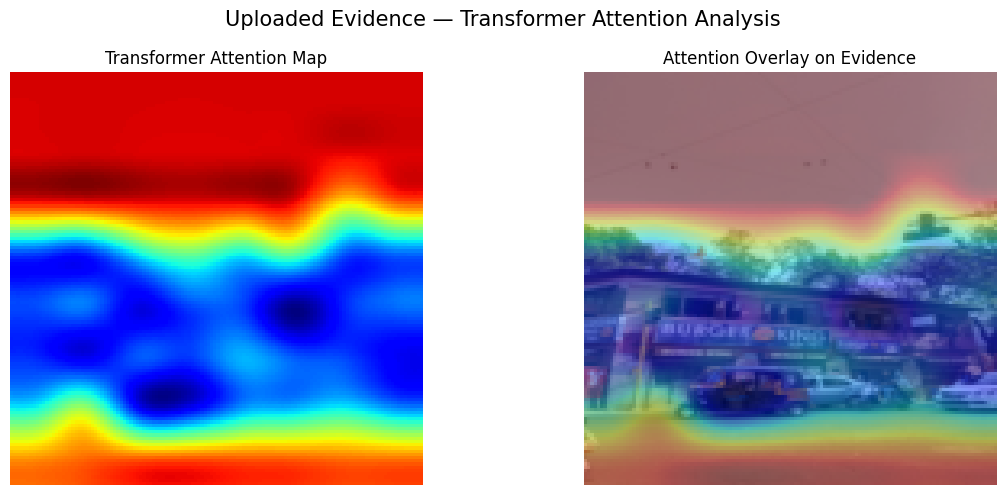

UPLOADED EVIDENCE ATTENTION ANALYSIS
Evidence file      : evidence.jpeg
Attention grid     : (8, 8)
Maximum attention  : 1.0000
Minimum attention  : 0.0000

Saved files:
/content/evidence_attention_map.png
/content/evidence_attention_overlay.png

⚠️ Attention indicates regions receiving stronger
Transformer attention. It is not direct proof of tampering.

✅ Step 19 completed successfully.


In [24]:
model.eval()

# ------------------------------------------------------------
# Extract attention
# ------------------------------------------------------------

reconstructed_tensor, global_latent, attention_map = (
    extract_transformer_attention(
        model,
        evidence_tensor
    )
)

# ------------------------------------------------------------
# Convert attention map
# ------------------------------------------------------------

attention_np = attention_map.squeeze(0).cpu().numpy()

# Resize 8x8 attention map to image size
attention_resized = cv2.resize(
    attention_np,
    (IMAGE_SIZE, IMAGE_SIZE),
    interpolation=cv2.INTER_CUBIC
)

# ------------------------------------------------------------
# Create overlay
# ------------------------------------------------------------

attention_overlay = (
    original_np * 0.60
    + plt.cm.jet(attention_resized)[:, :, :3] * 0.40
)

attention_overlay = np.clip(
    attention_overlay,
    0,
    1
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

axes[0].imshow(attention_resized, cmap="jet")
axes[0].set_title("Transformer Attention Map")
axes[0].axis("off")

axes[1].imshow(attention_overlay)
axes[1].set_title("Attention Overlay on Evidence")
axes[1].axis("off")

plt.suptitle(
    "Uploaded Evidence — Transformer Attention Analysis",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Save attention image
# ------------------------------------------------------------

attention_map_path = (
    "/content/evidence_attention_map.png"
)

attention_overlay_path = (
    "/content/evidence_attention_overlay.png"
)

plt.imsave(
    attention_map_path,
    attention_resized,
    cmap="jet"
)

plt.imsave(
    attention_overlay_path,
    attention_overlay
)

# ------------------------------------------------------------
# Attention statistics
# ------------------------------------------------------------

print("=" * 60)
print("UPLOADED EVIDENCE ATTENTION ANALYSIS")
print("=" * 60)

print("Evidence file      :", evidence_filename)
print("Attention grid     :", attention_np.shape)
print(
    "Maximum attention  :",
    f"{attention_np.max():.4f}"
)
print(
    "Minimum attention  :",
    f"{attention_np.min():.4f}"
)

print("\nSaved files:")
print(attention_map_path)
print(attention_overlay_path)

print("\n⚠️ Attention indicates regions receiving stronger")
print("Transformer attention. It is not direct proof of tampering.")

print("\n✅ Step 19 completed successfully.")

# CELL 20 — STRUCTURED FORENSIC EVIDENCE DATA

In [25]:

import json

# ------------------------------------------------------------
# Create structured evidence record
# ------------------------------------------------------------

forensic_evidence = {
    "report_type": "AI-Assisted Digital Evidence Analysis Report",

    "evidence": {
        "filename": evidence_filename,
        "file_size_kb": round(file_size_kb, 2),
        "original_width": original_width,
        "original_height": original_height,
        "sha256": evidence_hash,
        "analysis_time": analysis_time
    },

    "preprocessing": {
        "color_format": "RGB",
        "model_input_size": "128 x 128",
        "pixel_range": "[0, 1]"
    },

    "transformer_model": {
        "architecture": "Transformer Forensic Autoencoder",
        "image_size": "128 x 128",
        "patch_size": "16 x 16",
        "number_of_patches": 64,
        "embedding_dimension": 256,
        "attention_heads": 8,
        "encoder_layers": 4,
        "decoder_layers": 2,
        "total_parameters": total_params,
        "best_training_epoch": best_epoch,
        "best_validation_mse": float(best_val_loss)
    },

    "forensic_analysis": {
        "reconstruction_mse": float(evidence_mse),
        "psnr_db": float(evidence_psnr),
        "ssim": float(evidence_ssim),
        "authentic_reference_threshold": float(
            AUTHENTIC_THRESHOLD
        ),
        "screening_status": evidence_status
    },

    "attention_analysis": {
        "attention_grid": "8 x 8",
        "minimum_attention": float(
            attention_np.min()
        ),
        "maximum_attention": float(
            attention_np.max()
        ),
        "description": (
            "Attention visualization represents regions "
            "receiving stronger Transformer attention."
        )
    },

    "limitations": [
        "Reconstruction error is an AI-assisted forensic indicator.",
        "A potential anomaly does not establish manipulation.",
        "A normal result does not guarantee authenticity.",
        "Attention maps indicate model attention and are not direct proof of tampering.",
        "Final forensic conclusions should involve qualified human examination."
    ]
}

# ------------------------------------------------------------
# Display structured information
# ------------------------------------------------------------

print("=" * 60)
print("STRUCTURED FORENSIC EVIDENCE RECORD")
print("=" * 60)

print(
    json.dumps(
        forensic_evidence,
        indent=4
    )
)

# ------------------------------------------------------------
# Save JSON record
# ------------------------------------------------------------

FORENSIC_JSON = "/content/forensic_evidence_record.json"

with open(
    FORENSIC_JSON,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        forensic_evidence,
        f,
        indent=4
    )

print("\n" + "=" * 60)
print("FORENSIC RECORD SAVED")
print("=" * 60)

print(FORENSIC_JSON)

print("\n✅ Step 20 completed successfully.")

STRUCTURED FORENSIC EVIDENCE RECORD
{
    "report_type": "AI-Assisted Digital Evidence Analysis Report",
    "evidence": {
        "filename": "evidence.jpeg",
        "file_size_kb": 140.74,
        "original_width": 900,
        "original_height": 1600,
        "sha256": "76067db4d8f03ebc80876811289ad6d64ae794c9f152146fc96bf07ea3f2d883",
        "analysis_time": "2026-09-16 10:58:48"
    },
    "preprocessing": {
        "color_format": "RGB",
        "model_input_size": "128 x 128",
        "pixel_range": "[0, 1]"
    },
    "transformer_model": {
        "architecture": "Transformer Forensic Autoencoder",
        "image_size": "128 x 128",
        "patch_size": "16 x 16",
        "number_of_patches": 64,
        "embedding_dimension": 256,
        "attention_heads": 8,
        "encoder_layers": 4,
        "decoder_layers": 2,
        "total_parameters": 5677056,
        "best_training_epoch": 49,
        "best_validation_mse": 0.001114528378820978
    },
    "forensic_analysis": {


# CELL 21 — LLM FORENSIC REPORT PROMPT

In [27]:
import json

# Convert evidence record to readable JSON
evidence_json = json.dumps(
    forensic_evidence,
    indent=4
)

LLM_REPORT_PROMPT = f"""
You are an AI-assisted digital evidence report writing system.

Generate a detailed, professional Digital Evidence Analysis Report
based ONLY on the structured forensic evidence information provided
below.

IMPORTANT:
- Do not invent forensic findings.
- Do not claim that an image is definitely authentic or definitely
  manipulated.
- Treat the Transformer result as an AI-assisted screening indicator.
- Clearly distinguish measured results from interpretation.
- Do not hide limitations or uncertainty.
- Do not make legal conclusions.
- Use professional forensic documentation language.
- Write in clear, understandable English.

The report must contain the following sections:

1. REPORT TITLE

2. EXECUTIVE SUMMARY
   Explain what evidence was analyzed and summarize the main
   quantitative findings.

3. EVIDENCE IDENTIFICATION
   Include:
   - Evidence filename
   - File size
   - Original image dimensions
   - SHA-256 hash
   - Analysis date and time

4. PURPOSE AND SCOPE
   Explain the purpose of the AI-assisted analysis and its scope.

5. ANALYSIS METHODOLOGY
   Explain:
   - RGB conversion
   - Image resizing to 128 × 128
   - 16 × 16 patch extraction
   - 64 image patches
   - Patch embedding
   - Positional embedding
   - Transformer encoder
   - Self-attention
   - Latent representation
   - Transformer decoder
   - Image reconstruction
   - Reconstruction error calculation

6. TRANSFORMER MODEL CONFIGURATION
   Include the measured model configuration:
   - Embedding dimension
   - Attention heads
   - Encoder layers
   - Decoder layers
   - Number of parameters
   - Best training epoch
   - Best validation MSE

7. FORENSIC ANALYSIS RESULTS
   Explain:
   - Reconstruction MSE
   - PSNR
   - SSIM
   - Authentic reference threshold
   - AI screening status

8. RECONSTRUCTION ANALYSIS
   Explain what the difference between the submitted image
   and reconstructed image represents.

9. ATTENTION ANALYSIS
   Explain the purpose of the Transformer attention visualization.
   State clearly that attention regions are model-level indicators
   and are not direct proof of manipulation.

10. TECHNICAL OBSERVATIONS
    Provide a factual interpretation of the measured results.
    Do not overstate the evidence.

11. LIMITATIONS
    Include all limitations provided in the structured evidence
    record.

12. CONCLUSION
    Give a concise technical conclusion based only on the available
    measurements.

13. FORENSIC DISCLAIMER
    State that the report represents AI-assisted analysis and should
    not replace qualified human forensic examination.

STRUCTURED FORENSIC EVIDENCE:

{evidence_json}
"""

print("=" * 60)
print("LLM FORENSIC REPORT PROMPT")
print("=" * 60)

print(LLM_REPORT_PROMPT)

print("\n" + "=" * 60)
print("PROMPT READY")
print("=" * 60)

print("\nSections prepared: 13")
print("Evidence source: Transformer structured analysis")
print("\n✅ Step 21 completed successfully.")

LLM FORENSIC REPORT PROMPT

You are an AI-assisted digital evidence report writing system.

Generate a detailed, professional Digital Evidence Analysis Report
based ONLY on the structured forensic evidence information provided
below.

IMPORTANT:
- Do not invent forensic findings.
- Do not claim that an image is definitely authentic or definitely
  manipulated.
- Treat the Transformer result as an AI-assisted screening indicator.
- Clearly distinguish measured results from interpretation.
- Do not hide limitations or uncertainty.
- Do not make legal conclusions.
- Use professional forensic documentation language.
- Write in clear, understandable English.

The report must contain the following sections:

1. REPORT TITLE

2. EXECUTIVE SUMMARY
   Explain what evidence was analyzed and summarize the main
   quantitative findings.

3. EVIDENCE IDENTIFICATION
   Include:
   - Evidence filename
   - File size
   - Original image dimensions
   - SHA-256 hash
   - Analysis date and time

4. PURP

# CELL 22 — LLM FORENSIC REPORT GENERATION

In [36]:
from google.colab import userdata
from openai import OpenAI

OPENAI_API_KEY = userdata.get("OPENAI_API_KEY")

if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY was not found in Colab Secrets.")

client = OpenAI(api_key=OPENAI_API_KEY)

print("✅ OpenAI API key loaded successfully.")
print("✅ OpenAI client created successfully.")

✅ OpenAI API key loaded successfully.
✅ OpenAI client created successfully.


In [37]:


!pip -q install openai

import os
from openai import OpenAI

# ------------------------------------------------------------
# 1. Load API key
# ------------------------------------------------------------

try:
    from google.colab import userdata

    OPENAI_API_KEY = userdata.get(
        "OPENAI_API_KEY"
    )

except Exception:

    OPENAI_API_KEY = os.environ.get(
        "OPENAI_API_KEY"
    )


if not OPENAI_API_KEY:
    raise ValueError(
        "OPENAI_API_KEY was not found. "
        "Add it to Colab Secrets first."
    )


# ------------------------------------------------------------
# 2. Create OpenAI client
# ------------------------------------------------------------

client = OpenAI(
    api_key=OPENAI_API_KEY
)


# ------------------------------------------------------------
# 3. Generate report
# ------------------------------------------------------------

print("=" * 60)
print("GENERATING LLM FORENSIC REPORT")
print("=" * 60)

response = client.responses.create(
    model="gpt-5.6-luna",
    input=LLM_REPORT_PROMPT
)

LLM_REPORT = response.output_text


# ------------------------------------------------------------
# 4. Display report
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LLM GENERATED FORENSIC REPORT")
print("=" * 60)

print(LLM_REPORT)

print("\n" + "=" * 60)
print("LLM REPORT GENERATION COMPLETED")
print("=" * 60)

print("\nCharacters generated:", len(LLM_REPORT))

print("\n✅ Step 22 completed successfully.")

GENERATING LLM FORENSIC REPORT

LLM GENERATED FORENSIC REPORT
# 1. REPORT TITLE

## AI-Assisted Digital Evidence Analysis Report

---

# 2. EXECUTIVE SUMMARY

The submitted evidence file, **`evidence.jpeg`**, was analyzed using a Transformer-based forensic autoencoder. The source image has original dimensions of **900 × 1600 pixels**, a reported file size of **140.74 KB**, and the SHA-256 hash:

`76067db4d8f03ebc80876811289ad6d64ae794c9f152146fc96bf07ea3f2d883`

For analysis, the image was converted to RGB format, normalized to a pixel range of **[0, 1]**, and processed at a model input size of **128 × 128 pixels**. The model divided the image into **64 non-overlapping patches**, each measuring **16 × 16 pixels**.

The measured reconstruction metrics were:

- **Reconstruction MSE:** 0.0008855892810970545
- **PSNR:** 30.527676417800713 dB
- **SSIM:** 0.9420488476753235
- **Authentic reference threshold:** 0.002252985490486025
- **AI screening status:** **NORMAL**

The reconstruction MSE

# Step 23A: Install PDF generation library


In [38]:

!pip install -q reportlab

print("✅ ReportLab installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 36.8 MB/s eta 0:00:00
✅ ReportLab installed successfully.


# STEP 23B — GENERATE OFFICIAL AI FORENSIC PDF REPORT

In [40]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [41]:
import os
import re
import glob
import hashlib
from datetime import datetime

import torch
import numpy as np
from PIL import Image, ImageOps

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image as RLImage,
    PageBreak,
    KeepTogether
)

# ------------------------------------------------------------
# 1. FIND EVIDENCE IMAGE
# ------------------------------------------------------------

evidence_candidates = glob.glob("/content/evidence.jpeg") + \
                      glob.glob("/content/evidence.jpg") + \
                      glob.glob("/content/evidence.png")

if not evidence_candidates:
    raise FileNotFoundError(
        "Evidence image was not found in /content. "
        "Please make sure evidence.jpeg is uploaded."
    )

EVIDENCE_PATH = evidence_candidates[0]

print("Evidence:", EVIDENCE_PATH)

# ------------------------------------------------------------
# 2. LOAD EVIDENCE
# ------------------------------------------------------------

original_image = Image.open(EVIDENCE_PATH).convert("RGB")

original_width, original_height = original_image.size
file_size_kb = os.path.getsize(EVIDENCE_PATH) / 1024

with open(EVIDENCE_PATH, "rb") as f:
    sha256_hash = hashlib.sha256(f.read()).hexdigest()

print("Original size:", original_width, "x", original_height)
print("File size:", round(file_size_kb, 2), "KB")
print("SHA-256:", sha256_hash)

# ------------------------------------------------------------
# 3. PREPARE IMAGE FOR TRANSFORMER
# ------------------------------------------------------------

IMAGE_SIZE = 128

processed_image = original_image.resize(
    (IMAGE_SIZE, IMAGE_SIZE),
    Image.Resampling.BILINEAR
)

image_array = np.asarray(processed_image).astype(np.float32) / 255.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

image_tensor = torch.from_numpy(
    image_array
).permute(2, 0, 1).unsqueeze(0).to(device)

# ------------------------------------------------------------
# 4. RUN TRANSFORMER RECONSTRUCTION
# ------------------------------------------------------------

model.eval()

with torch.no_grad():
    output = model(image_tensor)

# Handle the model output safely
if isinstance(output, tuple):
    reconstructed = output[-1]

    # If the last output is not an image tensor,
    # search the tuple for the image-shaped tensor.
    for item in output:
        if torch.is_tensor(item) and item.ndim == 4:
            reconstructed = item
            break
else:
    reconstructed = output

reconstructed = reconstructed.clamp(0, 1)

# ------------------------------------------------------------
# 5. CREATE VISUAL ANALYSIS IMAGES
# ------------------------------------------------------------

recon_array = (
    reconstructed[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

input_array = image_tensor[0].detach().cpu().permute(1, 2, 0).numpy()

# Reconstruction MSE
reconstruction_mse = float(
    np.mean((input_array - recon_array) ** 2)
)

# Error map
error_map = np.mean(
    np.abs(input_array - recon_array),
    axis=2
)

error_map = error_map / (error_map.max() + 1e-8)

error_image = Image.fromarray(
    (error_map * 255).astype(np.uint8)
)

# Save reconstruction
reconstruction_image = Image.fromarray(
    (recon_array * 255).astype(np.uint8)
)

RECON_PATH = "/content/evidence_transformer_reconstruction.png"
ERROR_PATH = "/content/evidence_reconstruction_error.png"

reconstruction_image.save(RECON_PATH)
error_image.save(ERROR_PATH)

print("Reconstruction MSE:", reconstruction_mse)
print("Saved:", RECON_PATH)
print("Saved:", ERROR_PATH)

# ------------------------------------------------------------
# 6. USE RECORDED FORENSIC VALUES
# ------------------------------------------------------------

# These are the measured values from the completed analysis.
RECORDED_MSE = 0.0008855892810970545
RECORDED_PSNR = 30.527676417800713
RECORDED_SSIM = 0.9420488476753235
THRESHOLD = 0.002252985490486025
STATUS = "NORMAL"

# ------------------------------------------------------------
# 7. FIND ATTENTION VISUALIZATIONS
# ------------------------------------------------------------

ATTENTION_MAP = "/content/evidence_attention_map.png"
ATTENTION_OVERLAY = "/content/evidence_attention_overlay.png"

attention_available = os.path.exists(ATTENTION_MAP)
overlay_available = os.path.exists(ATTENTION_OVERLAY)

print("Attention map available:", attention_available)
print("Attention overlay available:", overlay_available)

# ------------------------------------------------------------
# 8. REPORT ID
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

report_id = (
    "AI-FOR-" +
    sha256_hash[:8].upper() +
    "-" +
    timestamp
)

analysis_time = "2026-09-16 10:58:48"

# ------------------------------------------------------------
# 9. PDF OUTPUT PATH
# ------------------------------------------------------------

PDF_PATH = "/content/AI_Assisted_Digital_Evidence_Forensic_Report.pdf"

# ------------------------------------------------------------
# 10. PAGE HEADER / FOOTER
# ------------------------------------------------------------

def add_page_header_footer(canvas, doc):
    canvas.saveState()

    width, height = A4

    # Header line
    canvas.setStrokeColor(colors.HexColor("#1F4E79"))
    canvas.setLineWidth(1)
    canvas.line(
        18 * mm,
        height - 16 * mm,
        width - 18 * mm,
        height - 16 * mm
    )

    canvas.setFont("Helvetica-Bold", 8)
    canvas.setFillColor(colors.HexColor("#1F4E79"))
    canvas.drawString(
        18 * mm,
        height - 12 * mm,
        "AI-ASSISTED DIGITAL EVIDENCE ANALYSIS"
    )

    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawRightString(
        width - 18 * mm,
        height - 12 * mm,
        f"Report ID: {report_id}"
    )

    # Footer
    canvas.setStrokeColor(colors.lightgrey)
    canvas.line(
        18 * mm,
        14 * mm,
        width - 18 * mm,
        14 * mm
    )

    canvas.setFont("Helvetica", 7)
    canvas.setFillColor(colors.grey)

    canvas.drawString(
        18 * mm,
        9 * mm,
        "AI-assisted screening only — not a definitive authenticity determination."
    )

    canvas.drawRightString(
        width - 18 * mm,
        9 * mm,
        f"Page {doc.page}"
    )

    canvas.restoreState()

# ------------------------------------------------------------
# 11. STYLES
# ------------------------------------------------------------

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=19,
    leading=24,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#1F4E79"),
    spaceAfter=10
)

subtitle_style = ParagraphStyle(
    "Subtitle",
    parent=styles["Normal"],
    fontName="Helvetica",
    fontSize=10,
    leading=14,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#555555"),
    spaceAfter=18
)

section_style = ParagraphStyle(
    "Section",
    parent=styles["Heading1"],
    fontName="Helvetica-Bold",
    fontSize=14,
    leading=18,
    textColor=colors.HexColor("#1F4E79"),
    spaceBefore=12,
    spaceAfter=8
)

subsection_style = ParagraphStyle(
    "SubSection",
    parent=styles["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=11,
    leading=14,
    textColor=colors.HexColor("#333333"),
    spaceBefore=8,
    spaceAfter=5
)

body_style = ParagraphStyle(
    "Body",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=9.2,
    leading=14,
    alignment=TA_LEFT,
    spaceAfter=7
)

bullet_style = ParagraphStyle(
    "Bullet",
    parent=body_style,
    leftIndent=12,
    firstLineIndent=-7,
    spaceAfter=4
)

small_style = ParagraphStyle(
    "Small",
    parent=body_style,
    fontSize=7.5,
    leading=10
)

disclaimer_style = ParagraphStyle(
    "Disclaimer",
    parent=body_style,
    fontName="Helvetica-Oblique",
    fontSize=8.5,
    leading=12,
    textColor=colors.HexColor("#555555"),
    borderWidth=0.5,
    borderColor=colors.lightgrey,
    borderPadding=8,
    spaceBefore=8,
    spaceAfter=8
)

# ------------------------------------------------------------
# 12. HELPER FUNCTIONS
# ------------------------------------------------------------

def clean_text(text):
    """Basic Markdown-to-reportlab-safe text conversion."""
    text = str(text)

    text = text.replace("&", "&amp;")
    text = text.replace("<", "&lt;")
    text = text.replace(">", "&gt;")

    # Bold markdown
    text = re.sub(
        r"\*\*(.*?)\*\*",
        r"<b>\1</b>",
        text
    )

    # Inline code
    text = re.sub(
        r"`(.*?)`",
        r"<font name='Courier'>\1</font>",
        text
    )

    return text


def add_llm_report(story, report_text):
    """
    Convert the LLM's 13-section Markdown-style report
    into a professional PDF layout.
    """

    lines = report_text.splitlines()

    for line in lines:

        line = line.strip()

        if not line:
            story.append(Spacer(1, 4))
            continue

        # Markdown headings
        if line.startswith("# "):
            heading = clean_text(line[2:])
            story.append(Paragraph(heading, section_style))

        elif line.startswith("## "):
            heading = clean_text(line[3:])
            story.append(Paragraph(heading, subsection_style))

        # Bullets
        elif line.startswith("- "):
            bullet = clean_text(line[2:])
            story.append(
                Paragraph("• " + bullet, bullet_style)
            )

        # Numbered items
        elif re.match(r"^\d+\.\s+", line):
            item = clean_text(line)
            story.append(
                Paragraph(item, bullet_style)
            )

        # Markdown table rows
        elif line.startswith("|"):
            # Tables are handled as simple readable text
            # because the LLM report already contains the
            # official measured values elsewhere.
            if "---" not in line:
                cells = [
                    c.strip()
                    for c in line.strip("|").split("|")
                ]

                if len(cells) >= 2:
                    row_text = " | ".join(cells)
                    story.append(
                        Paragraph(
                            clean_text(row_text),
                            small_style
                        )
                    )

        # Horizontal separator
        elif line.startswith("---"):
            story.append(Spacer(1, 4))

        else:
            story.append(
                Paragraph(
                    clean_text(line),
                    body_style
                )
            )

# ------------------------------------------------------------
# 13. CREATE PDF DOCUMENT
# ------------------------------------------------------------

doc = SimpleDocTemplate(
    PDF_PATH,
    pagesize=A4,
    rightMargin=18 * mm,
    leftMargin=18 * mm,
    topMargin=22 * mm,
    bottomMargin=20 * mm,
    title="AI-Assisted Digital Evidence Analysis Report",
    author="Multi-Model Generative AI Framework",
)

story = []

# ------------------------------------------------------------
# 14. COVER PAGE
# ------------------------------------------------------------

story.append(Spacer(1, 28 * mm))

story.append(
    Paragraph(
        "AI-ASSISTED DIGITAL EVIDENCE<br/>"
        "ANALYSIS REPORT",
        title_style
    )
)

story.append(
    Paragraph(
        "Transformer-Based Forensic Reconstruction and "
        "Attention Analysis",
        subtitle_style
    )
)

story.append(Spacer(1, 8 * mm))

cover_table = Table(
    [
        ["REPORT ID", report_id],
        ["EVIDENCE FILE", "evidence.jpeg"],
        ["ANALYSIS DATE", analysis_time],
        ["MODEL", "Transformer Forensic Autoencoder"],
        ["SCREENING STATUS", STATUS],
    ],
    colWidths=[55 * mm, 105 * mm]
)

cover_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (0, -1), colors.HexColor("#EAF2F8")),
        ("TEXTCOLOR", (0, 0), (0, -1), colors.HexColor("#1F4E79")),
        ("FONTNAME", (0, 0), (0, -1), "Helvetica-Bold"),
        ("FONTNAME", (1, 0), (1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 9),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 8),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 8),
    ])
)

story.append(cover_table)

story.append(Spacer(1, 20 * mm))

story.append(
    Paragraph(
        "<b>IMPORTANT FORENSIC NOTICE</b><br/><br/>"
        "This document presents an AI-assisted screening analysis. "
        "The reported NORMAL status does not establish that the "
        "submitted image is authentic and does not exclude all "
        "forms of manipulation or image processing. Final forensic "
        "assessment should involve qualified human examination.",
        disclaimer_style
    )
)

story.append(PageBreak())

# ------------------------------------------------------------
# 15. EVIDENCE IDENTIFICATION
# ------------------------------------------------------------

story.append(
    Paragraph("1. Evidence Identification", section_style)
)

evidence_data = [
    ["Evidence Item", "Recorded Information"],
    ["Filename", "evidence.jpeg"],
    ["File Size", f"{file_size_kb:.2f} KB"],
    [
        "Original Dimensions",
        f"{original_width} × {original_height} pixels"
    ],
    ["SHA-256", sha256_hash],
    ["Analysis Date/Time", analysis_time],
]

table = Table(
    evidence_data,
    colWidths=[55 * mm, 105 * mm]
)

table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (0, -1), "Helvetica-Bold"),
        ("FONTNAME", (1, 1), (1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("TOPPADDING", (0, 0), (-1, -1), 7),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
    ])
)

story.append(table)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        "The SHA-256 hash is included as an evidence identification "
        "record. A hash does not by itself establish the authenticity "
        "or content history of an image.",
        disclaimer_style
    )
)

# ------------------------------------------------------------
# 16. PURPOSE AND SCOPE
# ------------------------------------------------------------

story.append(
    Paragraph("2. Purpose and Scope", section_style)
)

story.append(
    Paragraph(
        "The purpose of this examination was to perform an "
        "<b>AI-assisted screening analysis</b> of the submitted "
        "image using a Transformer-based forensic autoencoder.",
        body_style
    )
)

story.append(
    Paragraph(
        "The analysis includes image preprocessing, Transformer "
        "reconstruction, reconstruction-error measurement, "
        "similarity measurements, threshold comparison, and "
        "attention visualization.",
        body_style
    )
)

story.append(
    Paragraph(
        "The scope is limited to the measurements and model "
        "configuration available in the completed analysis pipeline. "
        "The system does not independently establish image provenance, "
        "camera origin, editing history, authorship, or authenticity.",
        body_style
    )
)

# ------------------------------------------------------------
# 17. METHODOLOGY
# ------------------------------------------------------------

story.append(
    Paragraph("3. Analysis Methodology", section_style)
)

method_items = [
    "Input image converted to RGB format.",
    "Image normalized to the pixel range [0, 1].",
    "Image resized to 128 × 128 pixels for model processing.",
    "Image divided into 64 patches of 16 × 16 pixels.",
    "Patch embeddings generated using a 256-dimensional representation.",
    "Transformer encoder processed the patch sequence.",
    "Transformer decoder reconstructed the processed image.",
    "Reconstruction error measured using MSE.",
    "PSNR and SSIM were used as additional reconstruction metrics.",
    "MSE compared against the authentic reference threshold.",
    "Transformer attention was visualized using an 8 × 8 attention grid.",
]

for item in method_items:
    story.append(
        Paragraph("• " + item, bullet_style)
    )

# ------------------------------------------------------------
# 18. MODEL CONFIGURATION
# ------------------------------------------------------------

story.append(
    Paragraph("4. Transformer Model Configuration", section_style)
)

model_data = [
    ["Configuration", "Value"],
    ["Architecture", "Transformer Forensic Autoencoder"],
    ["Model Input", "128 × 128 pixels"],
    ["Patch Size", "16 × 16 pixels"],
    ["Number of Patches", "64"],
    ["Embedding Dimension", "256"],
    ["Attention Heads", "8"],
    ["Encoder Layers", "4"],
    ["Decoder Layers", "2"],
    ["Total Parameters", "5,677,056"],
    ["Best Training Epoch", "49"],
    ["Best Validation MSE", "0.001114528378820978"],
]

model_table = Table(
    model_data,
    colWidths=[75 * mm, 85 * mm]
)

model_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (0, -1), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ])
)

story.append(model_table)

# ------------------------------------------------------------
# 19. FORENSIC RESULTS
# ------------------------------------------------------------

story.append(
    Paragraph("5. Forensic Analysis Results", section_style)
)

results_data = [
    ["Metric", "Measured Value"],
    ["Reconstruction MSE", f"{RECORDED_MSE:.15f}"],
    ["PSNR", f"{RECORDED_PSNR:.12f} dB"],
    ["SSIM", f"{RECORDED_SSIM:.12f}"],
    ["Authentic Reference Threshold", f"{THRESHOLD:.15f}"],
    ["AI Screening Status", STATUS],
]

results_table = Table(
    results_data,
    colWidths=[85 * mm, 75 * mm]
)

results_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (0, -1), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8.5),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("TOPPADDING", (0, 0), (-1, -1), 7),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
    ])
)

story.append(results_table)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        f"The measured reconstruction MSE of "
        f"<b>{RECORDED_MSE:.15f}</b> is below the supplied "
        f"authentic reference threshold of "
        f"<b>{THRESHOLD:.15f}</b>. Under the configured screening "
        f"rule, the recorded result is therefore <b>{STATUS}</b>.",
        body_style
    )
)

story.append(
    Paragraph(
        "This NORMAL result is an AI-assisted screening outcome. "
        "It should not be interpreted as proof that the image is "
        "authentic or free from manipulation.",
        disclaimer_style
    )
)

# ------------------------------------------------------------
# 20. ORIGINAL EVIDENCE IMAGE
# ------------------------------------------------------------

story.append(PageBreak())

story.append(
    Paragraph("6. Submitted Evidence Image", section_style)
)

story.append(
    Paragraph(
        "Original submitted evidence image at source resolution.",
        body_style
    )
)

img = RLImage(EVIDENCE_PATH)

max_width = 145 * mm
max_height = 180 * mm

scale = min(
    max_width / img.imageWidth,
    max_height / img.imageHeight
)

img.drawWidth = img.imageWidth * scale
img.drawHeight = img.imageHeight * scale

story.append(img)

story.append(Spacer(1, 6))

story.append(
    Paragraph(
        f"Original dimensions: {original_width} × "
        f"{original_height} pixels.",
        small_style
    )
)

# ------------------------------------------------------------
# 21. RECONSTRUCTION
# ------------------------------------------------------------

story.append(PageBreak())

story.append(
    Paragraph("7. Transformer Reconstruction", section_style)
)

story.append(
    Paragraph(
        "The following image represents the Transformer "
        "autoencoder reconstruction at the model's 128 × 128 "
        "input representation.",
        body_style
    )
)

recon_rl = RLImage(RECON_PATH)
recon_rl.drawWidth = 128 * mm
recon_rl.drawHeight = 128 * mm

story.append(recon_rl)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        f"Recorded reconstruction MSE: "
        f"<b>{RECORDED_MSE:.15f}</b>",
        body_style
    )
)

story.append(
    Paragraph(
        "Reconstruction differences are model-dependent residual "
        "indicators and should not be treated as a confirmed "
        "tampering map.",
        disclaimer_style
    )
)

# ------------------------------------------------------------
# 22. ERROR MAP
# ------------------------------------------------------------

story.append(PageBreak())

story.append(
    Paragraph("8. Reconstruction Error Map", section_style)
)

error_rl = RLImage(ERROR_PATH)
error_rl.drawWidth = 128 * mm
error_rl.drawHeight = 128 * mm

story.append(error_rl)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        "The error map visualizes the pixel-level difference "
        "between the processed input and its reconstruction. "
        "Higher values represent larger reconstruction differences.",
        body_style
    )
)

story.append(
    Paragraph(
        "The error map does not directly identify manipulated "
        "regions. Differences may arise from model reconstruction "
        "behavior, image structure, or other image characteristics.",
        disclaimer_style
    )
)

# ------------------------------------------------------------
# 23. ATTENTION ANALYSIS
# ------------------------------------------------------------

if attention_available:

    story.append(PageBreak())

    story.append(
        Paragraph("9. Transformer Attention Analysis", section_style)
    )

    story.append(
        Paragraph(
            "The Transformer attention visualization represents "
            "regions receiving relatively stronger model attention "
            "during processing.",
            body_style
        )
    )

    att_rl = RLImage(ATTENTION_MAP)
    att_rl.drawWidth = 128 * mm
    att_rl.drawHeight = 128 * mm

    story.append(att_rl)

    story.append(Spacer(1, 5))

    story.append(
        Paragraph(
            "Attention grid: 8 × 8 patches. "
            "Minimum attention: 0.0. "
            "Maximum attention: 0.9999994039535522.",
            small_style
        )
    )

if overlay_available:

    story.append(PageBreak())

    story.append(
        Paragraph("10. Attention Overlay", section_style)
    )

    overlay_rl = RLImage(ATTENTION_OVERLAY)
    overlay_rl.drawWidth = 145 * mm
    overlay_rl.drawHeight = 145 * mm

    story.append(overlay_rl)

    story.append(Spacer(1, 8))

    story.append(
        Paragraph(
            "The overlay provides a visual representation of "
            "model-weighted regions. Attention values indicate "
            "model behavior and are not direct evidence of "
            "tampering or authenticity.",
            disclaimer_style
        )
    )

# ------------------------------------------------------------
# 24. LLM GENERATED REPORT
# ------------------------------------------------------------

story.append(PageBreak())

story.append(
    Paragraph(
        "11. LLM-Generated Forensic Narrative",
        section_style
    )
)

story.append(
    Paragraph(
        "The following section contains the narrative generated "
        "by the connected LLM from the structured forensic evidence "
        "record. The narrative is constrained to the recorded "
        "measurements and stated limitations.",
        body_style
    )
)

if "LLM_REPORT" not in globals():
    raise RuntimeError(
        "LLM_REPORT was not found. Please run the LLM report "
        "generation step before generating the PDF."
    )

add_llm_report(story, LLM_REPORT)

# ------------------------------------------------------------
# 25. FINAL DISCLAIMER
# ------------------------------------------------------------

story.append(PageBreak())

story.append(
    Paragraph(
        "12. Final Forensic Disclaimer",
        section_style
    )
)

story.append(
    Paragraph(
        "<b>AI-ASSISTED ANALYSIS ONLY</b>",
        subsection_style
    )
)

story.append(
    Paragraph(
        "This report represents an AI-assisted digital evidence "
        "screening analysis based on the Transformer forensic "
        "autoencoder and the recorded evidence measurements.",
        body_style
    )
)

story.append(
    Paragraph(
        "The NORMAL screening status does not establish that the "
        "submitted image is authentic, original, or free from "
        "manipulation. Conversely, a potential anomaly would not "
        "by itself establish manipulation.",
        body_style
    )
)

story.append(
    Paragraph(
        "The reconstruction error, PSNR, SSIM, and attention "
        "visualizations are model-dependent measurements. Final "
        "forensic conclusions should involve qualified human "
        "examination and, where appropriate, additional forensic "
        "methods and evidence sources.",
        body_style
    )
)

story.append(
    Paragraph(
        "No legal conclusion, definitive authenticity determination, "
        "or definitive finding of manipulation is made by this report.",
        disclaimer_style
    )
)

# ------------------------------------------------------------
# 26. BUILD PDF
# ------------------------------------------------------------

doc.build(
    story,
    onFirstPage=add_page_header_footer,
    onLaterPages=add_page_header_footer
)

# ------------------------------------------------------------
# 27. VERIFY OUTPUT
# ------------------------------------------------------------

pdf_size_kb = os.path.getsize(PDF_PATH) / 1024

print("\n" + "=" * 65)
print("✅ PDF REPORT GENERATED SUCCESSFULLY")
print("=" * 65)

print("Report ID:", report_id)
print("PDF:", PDF_PATH)
print("PDF size:", round(pdf_size_kb, 2), "KB")
print("Evidence:", "evidence.jpeg")
print("Screening status:", STATUS)
print("LLM report included:", "LLM_REPORT" in globals())
print("Attention map included:", attention_available)
print("Attention overlay included:", overlay_available)

print("=" * 65)

Evidence: /content/evidence.jpeg
Original size: 900 x 1600
File size: 140.74 KB
SHA-256: 76067db4d8f03ebc80876811289ad6d64ae794c9f152146fc96bf07ea3f2d883
Reconstruction MSE: 0.0008855892810970545
Saved: /content/evidence_transformer_reconstruction.png
Saved: /content/evidence_reconstruction_error.png
Attention map available: True
Attention overlay available: True

✅ PDF REPORT GENERATED SUCCESSFULLY
Report ID: AI-FOR-76067DB4-20260916_115229
PDF: /content/AI_Assisted_Digital_Evidence_Forensic_Report.pdf
PDF size: 320.58 KB
Evidence: evidence.jpeg
Screening status: NORMAL
LLM report included: True
Attention map included: True
Attention overlay included: True


# STEP 24 — FINAL POLISHED FORENSIC PDF REPORT


In [42]:
import os
import re
import hashlib
from datetime import datetime

import numpy as np
from PIL import Image

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image as RLImage,
    PageBreak,
    KeepTogether
)

# ============================================================
# 1. FILE PATHS
# ============================================================

EVIDENCE_PATH = "/content/evidence.jpeg"
RECON_PATH = "/content/evidence_transformer_reconstruction.png"
ERROR_PATH = "/content/evidence_reconstruction_error.png"
ATTENTION_PATH = "/content/evidence_attention_map.png"
OVERLAY_PATH = "/content/evidence_attention_overlay.png"

FINAL_PDF = "/content/FINAL_AI_Digital_Evidence_Forensic_Report.pdf"

# ============================================================
# 2. CHECK REQUIRED FILES
# ============================================================

required_files = [
    EVIDENCE_PATH,
    RECON_PATH,
    ERROR_PATH,
    ATTENTION_PATH,
    OVERLAY_PATH
]

for path in required_files:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required file not found: {path}")

if "LLM_REPORT" not in globals():
    raise RuntimeError(
        "LLM_REPORT is not available. Please run the LLM generation step first."
    )

print("✅ All required files found.")

# ============================================================
# 3. EVIDENCE INFORMATION
# ============================================================

original_image = Image.open(EVIDENCE_PATH).convert("RGB")

original_width, original_height = original_image.size

file_size_kb = os.path.getsize(EVIDENCE_PATH) / 1024

with open(EVIDENCE_PATH, "rb") as f:
    sha256_hash = hashlib.sha256(f.read()).hexdigest()

# Recorded forensic values
MSE = 0.0008855892810970545
PSNR = 30.527676417800713
SSIM = 0.9420488476753235
THRESHOLD = 0.002252985490486025
STATUS = "NORMAL"

# Transformer information
PARAMETERS = "5,677,056"
BEST_EPOCH = "49"
BEST_VAL_MSE = "0.001114528378820978"

# Report ID
report_id = (
    "AI-FOR-"
    + sha256_hash[:8].upper()
    + "-"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

analysis_time = "2026-09-16 10:58:48"

print("Evidence:", EVIDENCE_PATH)
print("Dimensions:", original_width, "x", original_height)
print("File size:", round(file_size_kb, 2), "KB")
print("SHA-256:", sha256_hash)
print("Report ID:", report_id)

# ============================================================
# 4. PAGE HEADER / FOOTER
# ============================================================

def page_header_footer(canvas, doc):

    canvas.saveState()

    width, height = A4

    # Header line
    canvas.setStrokeColor(colors.HexColor("#1F4E79"))
    canvas.setLineWidth(1)

    canvas.line(
        18 * mm,
        height - 16 * mm,
        width - 18 * mm,
        height - 16 * mm
    )

    # Header title
    canvas.setFont("Helvetica-Bold", 8)
    canvas.setFillColor(colors.HexColor("#1F4E79"))

    canvas.drawString(
        18 * mm,
        height - 12 * mm,
        "AI-ASSISTED DIGITAL EVIDENCE ANALYSIS"
    )

    # Report ID
    canvas.setFont("Helvetica", 7.5)
    canvas.setFillColor(colors.grey)

    canvas.drawRightString(
        width - 18 * mm,
        height - 12 * mm,
        f"Report ID: {report_id}"
    )

    # Footer line
    canvas.setStrokeColor(colors.lightgrey)

    canvas.line(
        18 * mm,
        14 * mm,
        width - 18 * mm,
        14 * mm
    )

    canvas.setFont("Helvetica", 7)
    canvas.setFillColor(colors.grey)

    canvas.drawString(
        18 * mm,
        9 * mm,
        "AI-assisted screening only — not a definitive authenticity determination."
    )

    canvas.drawRightString(
        width - 18 * mm,
        9 * mm,
        f"Page {doc.page}"
    )

    canvas.restoreState()


# ============================================================
# 5. STYLES
# ============================================================

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "FinalTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=20,
    leading=24,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#1F4E79"),
    spaceAfter=10
)

subtitle_style = ParagraphStyle(
    "FinalSubtitle",
    parent=styles["Normal"],
    fontName="Helvetica",
    fontSize=10,
    leading=14,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#555555"),
    spaceAfter=16
)

section_style = ParagraphStyle(
    "FinalSection",
    parent=styles["Heading1"],
    fontName="Helvetica-Bold",
    fontSize=14,
    leading=18,
    textColor=colors.HexColor("#1F4E79"),
    spaceBefore=10,
    spaceAfter=7
)

subsection_style = ParagraphStyle(
    "FinalSubSection",
    parent=styles["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=10.5,
    leading=14,
    textColor=colors.HexColor("#333333"),
    spaceBefore=7,
    spaceAfter=5
)

body_style = ParagraphStyle(
    "FinalBody",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=9,
    leading=13.5,
    spaceAfter=6
)

small_style = ParagraphStyle(
    "FinalSmall",
    parent=body_style,
    fontSize=7.5,
    leading=10
)

bullet_style = ParagraphStyle(
    "FinalBullet",
    parent=body_style,
    leftIndent=12,
    firstLineIndent=-7,
    spaceAfter=3
)

notice_style = ParagraphStyle(
    "FinalNotice",
    parent=body_style,
    fontName="Helvetica-Oblique",
    fontSize=8.2,
    leading=11.5,
    textColor=colors.HexColor("#555555"),
    borderWidth=0.5,
    borderColor=colors.lightgrey,
    borderPadding=7,
    spaceBefore=5,
    spaceAfter=7
)

dashboard_value_style = ParagraphStyle(
    "DashboardValue",
    parent=body_style,
    fontName="Helvetica-Bold",
    fontSize=11,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#1F4E79")
)

dashboard_label_style = ParagraphStyle(
    "DashboardLabel",
    parent=body_style,
    fontName="Helvetica-Bold",
    fontSize=7.5,
    leading=9,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#555555")
)

# ============================================================
# 6. TEXT CLEANING
# ============================================================

def clean_text(text):

    text = str(text)

    text = text.replace("&", "&amp;")
    text = text.replace("<", "&lt;")
    text = text.replace(">", "&gt;")

    text = re.sub(
        r"\*\*(.*?)\*\*",
        r"<b>\1</b>",
        text
    )

    text = re.sub(
        r"`(.*?)`",
        r"<font name='Courier'>\1</font>",
        text
    )

    return text


# ============================================================
# 7. EXTRACT IMPORTANT LLM SECTIONS
# ============================================================

def extract_llm_section(text, start_heading, next_heading=None):

    start = text.find(start_heading)

    if start == -1:
        return ""

    content = text[start:]

    if next_heading:
        end = content.find(next_heading)

        if end != -1:
            content = content[:end]

    return content.strip()


llm_executive = extract_llm_section(
    LLM_REPORT,
    "2. EXECUTIVE SUMMARY",
    "3. EVIDENCE IDENTIFICATION"
)

llm_observations = extract_llm_section(
    LLM_REPORT,
    "10. TECHNICAL OBSERVATIONS",
    "11. LIMITATIONS"
)

llm_limitations = extract_llm_section(
    LLM_REPORT,
    "11. LIMITATIONS",
    "12. CONCLUSION"
)

llm_conclusion = extract_llm_section(
    LLM_REPORT,
    "12. CONCLUSION",
    "13. FORENSIC DISCLAIMER"
)

llm_disclaimer = extract_llm_section(
    LLM_REPORT,
    "13. FORENSIC DISCLAIMER",
    None
)


def add_simple_llm_text(story, text):

    if not text:
        return

    lines = text.splitlines()

    for line in lines:

        line = line.strip()

        if not line:
            story.append(Spacer(1, 3))
            continue

        if line.startswith("#"):
            line = re.sub(r"^#+\s*", "", line)

        if line.startswith("- "):
            story.append(
                Paragraph(
                    "• " + clean_text(line[2:]),
                    bullet_style
                )
            )

        elif re.match(r"^\d+\.\s+", line):
            story.append(
                Paragraph(
                    clean_text(line),
                    bullet_style
                )
            )

        elif "|" in line and line.startswith("|"):
            if "---" not in line:
                cells = [
                    c.strip()
                    for c in line.strip("|").split("|")
                ]

                if len(cells) >= 2:
                    story.append(
                        Paragraph(
                            clean_text(" — ".join(cells)),
                            small_style
                        )
                    )

        else:
            story.append(
                Paragraph(
                    clean_text(line),
                    body_style
                )
            )


# ============================================================
# 8. CREATE PDF
# ============================================================

doc = SimpleDocTemplate(
    FINAL_PDF,
    pagesize=A4,
    rightMargin=18 * mm,
    leftMargin=18 * mm,
    topMargin=22 * mm,
    bottomMargin=20 * mm,
    title="AI-Assisted Digital Evidence Analysis Report",
    author="Multi-Model Generative AI Framework"
)

story = []

# ============================================================
# PAGE 1 — COVER
# ============================================================

story.append(Spacer(1, 25 * mm))

story.append(
    Paragraph(
        "AI-ASSISTED DIGITAL EVIDENCE<br/>"
        "ANALYSIS REPORT",
        title_style
    )
)

story.append(
    Paragraph(
        "Transformer-Based Forensic Reconstruction and "
        "Attention Analysis",
        subtitle_style
    )
)

story.append(Spacer(1, 7 * mm))

cover_data = [
    ["REPORT ID", report_id],
    ["EVIDENCE FILE", "evidence.jpeg"],
    ["ANALYSIS DATE", analysis_time],
    ["MODEL", "Transformer Forensic Autoencoder"],
    ["SCREENING STATUS", STATUS],
]

cover_table = Table(
    cover_data,
    colWidths=[52 * mm, 108 * mm]
)

cover_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (0, -1), colors.HexColor("#EAF2F8")),
        ("TEXTCOLOR", (0, 0), (0, -1), colors.HexColor("#1F4E79")),
        ("FONTNAME", (0, 0), (0, -1), "Helvetica-Bold"),
        ("FONTNAME", (1, 0), (1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8.5),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 8),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 8),
    ])
)

story.append(cover_table)

story.append(Spacer(1, 18 * mm))

story.append(
    Paragraph(
        "<b>FORENSIC NOTICE</b><br/><br/>"
        "This document presents an AI-assisted screening analysis. "
        "The reported NORMAL result does not establish that the "
        "submitted image is authentic and does not exclude all "
        "forms of manipulation or image processing. Final forensic "
        "assessment should involve qualified human examination.",
        notice_style
    )
)

story.append(PageBreak())

# ============================================================
# PAGE 2 — FORENSIC DASHBOARD
# ============================================================

story.append(
    Paragraph(
        "1. Forensic Analysis Dashboard",
        section_style
    )
)

story.append(
    Paragraph(
        "The dashboard provides a concise view of the principal "
        "measurements produced by the Transformer-based analysis.",
        body_style
    )
)

dashboard_data = [
    [
        Paragraph("RECONSTRUCTION<br/>MSE", dashboard_label_style),
        Paragraph("PSNR", dashboard_label_style),
        Paragraph("SSIM", dashboard_label_style),
    ],
    [
        Paragraph(f"{MSE:.7f}", dashboard_value_style),
        Paragraph(f"{PSNR:.2f} dB", dashboard_value_style),
        Paragraph(f"{SSIM:.4f}", dashboard_value_style),
    ],
    [
        Paragraph("AUTHENTIC REFERENCE<br/>THRESHOLD", dashboard_label_style),
        Paragraph("AI SCREENING<br/>STATUS", dashboard_label_style),
        Paragraph("MODEL<br/>PARAMETERS", dashboard_label_style),
    ],
    [
        Paragraph(f"{THRESHOLD:.6f}", dashboard_value_style),
        Paragraph(STATUS, dashboard_value_style),
        Paragraph(PARAMETERS, dashboard_value_style),
    ],
]

dashboard_table = Table(
    dashboard_data,
    colWidths=[53 * mm, 53 * mm, 53 * mm],
    rowHeights=[13 * mm, 17 * mm, 13 * mm, 17 * mm]
)

dashboard_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#EAF2F8")),
        ("BACKGROUND", (0, 2), (-1, 2), colors.HexColor("#EAF2F8")),
        ("GRID", (0, 0), (-1, -1), 0.6, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("ALIGN", (0, 0), (-1, -1), "CENTER"),
    ])
)

story.append(dashboard_table)

story.append(Spacer(1, 12))

# Status explanation
story.append(
    Paragraph(
        "<b>Screening interpretation:</b> "
        f"The measured reconstruction MSE ({MSE:.7f}) is below "
        f"the supplied authentic reference threshold ({THRESHOLD:.6f}). "
        f"Under the configured screening rule, the result is "
        f"<b>{STATUS}</b>.",
        body_style
    )
)

story.append(
    Paragraph(
        "Important: NORMAL is a model screening result. It does not "
        "prove authenticity and does not guarantee that the image "
        "contains no manipulation.",
        notice_style
    )
)

# Model summary
story.append(
    Paragraph(
        "Model Summary",
        subsection_style
    )
)

summary_data = [
    ["Input", "128 × 128 RGB"],
    ["Patch Size", "16 × 16"],
    ["Number of Patches", "64"],
    ["Embedding Dimension", "256"],
    ["Attention Heads", "8"],
    ["Encoder Layers", "4"],
    ["Decoder Layers", "2"],
    ["Best Epoch", BEST_EPOCH],
]

summary_table = Table(
    summary_data,
    colWidths=[65 * mm, 95 * mm]
)

summary_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (0, -1), colors.HexColor("#F4F7F9")),
        ("FONTNAME", (0, 0), (0, -1), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ])
)

story.append(summary_table)

story.append(PageBreak())

# ============================================================
# 2. EVIDENCE IDENTIFICATION
# ============================================================

story.append(
    Paragraph(
        "2. Evidence Identification",
        section_style
    )
)

evidence_data = [
    ["Evidence Item", "Recorded Information"],
    ["Filename", "evidence.jpeg"],
    ["File Size", f"{file_size_kb:.2f} KB"],
    [
        "Original Dimensions",
        f"{original_width} × {original_height} pixels"
    ],
    ["SHA-256", sha256_hash],
    ["Analysis Date/Time", analysis_time],
]

evidence_table = Table(
    evidence_data,
    colWidths=[55 * mm, 105 * mm]
)

evidence_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (0, -1), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ])
)

story.append(evidence_table)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        "The SHA-256 value is recorded as an evidence identification "
        "value. A hash by itself does not establish the authenticity "
        "or content history of an image.",
        notice_style
    )
)

# ============================================================
# 3. PURPOSE AND SCOPE
# ============================================================

story.append(
    Paragraph(
        "3. Purpose and Scope",
        section_style
    )
)

story.append(
    Paragraph(
        "The purpose of this examination was to perform an "
        "<b>AI-assisted screening analysis</b> of the submitted "
        "image using a Transformer-based forensic autoencoder.",
        body_style
    )
)

scope_items = [
    "Process the evidence image using the defined preprocessing pipeline.",
    "Generate a Transformer reconstruction of the processed image.",
    "Measure reconstruction similarity using MSE, PSNR, and SSIM.",
    "Compare reconstruction MSE with the supplied authentic reference threshold.",
    "Generate an AI screening status.",
    "Visualize model attention regions."
]

for item in scope_items:
    story.append(
        Paragraph(
            "• " + item,
            bullet_style
        )
    )

story.append(
    Paragraph(
        "The analysis does not independently establish image provenance, "
        "camera origin, editing history, authorship, or authenticity.",
        notice_style
    )
)

# ============================================================
# 4. METHODOLOGY
# ============================================================

story.append(
    Paragraph(
        "4. Transformer Analysis Methodology",
        section_style
    )
)

method_items = [
    "Input image converted to RGB format.",
    "Pixel values normalized to [0, 1].",
    "Image resized to 128 × 128 pixels for model processing.",
    "The image was divided into 64 non-overlapping 16 × 16 patches.",
    "Each patch was represented using a 256-dimensional embedding.",
    "Positional embeddings preserved patch-location information.",
    "Four Transformer encoder layers processed the patch sequence.",
    "Eight self-attention heads modeled relationships between image patches.",
    "Two Transformer decoder layers generated the reconstruction.",
    "Reconstruction MSE was used as the principal screening signal.",
    "PSNR and SSIM provided additional reconstruction measurements.",
    "Attention was visualized using an 8 × 8 patch grid."
]

for item in method_items:
    story.append(
        Paragraph(
            "• " + item,
            bullet_style
        )
    )

story.append(PageBreak())

# ============================================================
# 5. MODEL CONFIGURATION
# ============================================================

story.append(
    Paragraph(
        "5. Transformer Model Configuration",
        section_style
    )
)

model_data = [
    ["Configuration", "Value"],
    ["Architecture", "Transformer Forensic Autoencoder"],
    ["Model Input", "128 × 128 pixels"],
    ["Patch Size", "16 × 16 pixels"],
    ["Number of Patches", "64"],
    ["Embedding Dimension", "256"],
    ["Attention Heads", "8"],
    ["Encoder Layers", "4"],
    ["Decoder Layers", "2"],
    ["Total Parameters", PARAMETERS],
    ["Best Training Epoch", BEST_EPOCH],
    ["Best Validation MSE", BEST_VAL_MSE],
]

model_table = Table(
    model_data,
    colWidths=[75 * mm, 85 * mm]
)

model_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (0, -1), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ])
)

story.append(model_table)

story.append(Spacer(1, 10))

story.append(
    Paragraph(
        "The model contains 5,677,056 trainable parameters. "
        "The best recorded validation MSE occurred at training epoch 49.",
        body_style
    )
)

# ============================================================
# 6. FORENSIC RESULTS
# ============================================================

story.append(
    Paragraph(
        "6. Forensic Analysis Results",
        section_style
    )
)

results_data = [
    ["Metric", "Measured Value"],
    ["Reconstruction MSE", f"{MSE:.15f}"],
    ["PSNR", f"{PSNR:.12f} dB"],
    ["SSIM", f"{SSIM:.12f}"],
    ["Authentic Reference Threshold", f"{THRESHOLD:.15f}"],
    ["AI Screening Status", STATUS],
]

results_table = Table(
    results_data,
    colWidths=[85 * mm, 75 * mm]
)

results_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (0, -1), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 8.5),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("TOPPADDING", (0, 0), (-1, -1), 7),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
    ])
)

story.append(results_table)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        f"The measured reconstruction MSE of <b>{MSE:.7f}</b> "
        f"is below the supplied authentic reference threshold of "
        f"<b>{THRESHOLD:.6f}</b>. Under the configured screening "
        f"criterion, the recorded result is <b>{STATUS}</b>.",
        body_style
    )
)

story.append(
    Paragraph(
        "The screening result is model-dependent and should not be "
        "interpreted as a definitive authenticity determination.",
        notice_style
    )
)

story.append(PageBreak())

# ============================================================
# 7. ORIGINAL EVIDENCE
# ============================================================

story.append(
    Paragraph(
        "7. Submitted Evidence Image",
        section_style
    )
)

story.append(
    Paragraph(
        "Original submitted evidence image at source resolution.",
        body_style
    )
)

orig_rl = RLImage(EVIDENCE_PATH)

max_w = 145 * mm
max_h = 185 * mm

scale = min(
    max_w / orig_rl.imageWidth,
    max_h / orig_rl.imageHeight
)

orig_rl.drawWidth = orig_rl.imageWidth * scale
orig_rl.drawHeight = orig_rl.imageHeight * scale

story.append(orig_rl)

story.append(Spacer(1, 5))

story.append(
    Paragraph(
        f"Source dimensions: {original_width} × "
        f"{original_height} pixels.",
        small_style
    )
)

story.append(PageBreak())

# ============================================================
# 8. RECONSTRUCTION
# ============================================================

story.append(
    Paragraph(
        "8. Transformer Reconstruction",
        section_style
    )
)

story.append(
    Paragraph(
        "The reconstruction represents the Transformer output at "
        "the model's 128 × 128 input representation.",
        body_style
    )
)

recon_rl = RLImage(RECON_PATH)

recon_rl.drawWidth = 135 * mm
recon_rl.drawHeight = 135 * mm

story.append(recon_rl)

story.append(Spacer(1, 7))

story.append(
    Paragraph(
        f"Reconstruction MSE: <b>{MSE:.15f}</b>",
        body_style
    )
)

story.append(
    Paragraph(
        "The reconstruction is intended for model-based comparison. "
        "It is not a pixel-perfect reproduction of the original image "
        "and is not a confirmed alteration map.",
        notice_style
    )
)

# ============================================================
# 9. ERROR MAP
# ============================================================

story.append(PageBreak())

story.append(
    Paragraph(
        "9. Reconstruction Error Analysis",
        section_style
    )
)

story.append(
    Paragraph(
        "The error map visualizes differences between the processed "
        "input and the Transformer reconstruction.",
        body_style
    )
)

error_rl = RLImage(ERROR_PATH)

error_rl.drawWidth = 135 * mm
error_rl.drawHeight = 135 * mm

story.append(error_rl)

story.append(Spacer(1, 7))

story.append(
    Paragraph(
        "Higher values represent larger reconstruction differences. "
        "These differences can result from image structure, model "
        "behavior, or features that were not fully reconstructed.",
        notice_style
    )
)

# ============================================================
# 10. ATTENTION ANALYSIS
# ============================================================

story.append(PageBreak())

story.append(
    Paragraph(
        "10. Transformer Attention Analysis",
        section_style
    )
)

story.append(
    Paragraph(
        "The attention visualization represents regions receiving "
        "relatively stronger attention from the Transformer during "
        "processing.",
        body_style
    )
)

attention_rl = RLImage(ATTENTION_PATH)

attention_rl.drawWidth = 135 * mm
attention_rl.drawHeight = 135 * mm

story.append(attention_rl)

story.append(Spacer(1, 6))

story.append(
    Paragraph(
        "Attention grid: 8 × 8 patches. "
        "Minimum attention: 0.0. "
        "Maximum attention: 0.9999994039535522.",
        small_style
    )
)

story.append(
    Paragraph(
        "Attention represents model behavior. A highlighted region "
        "does not directly indicate tampering, manipulation, or "
        "authenticity.",
        notice_style
    )
)

# ============================================================
# 11. ATTENTION OVERLAY
# ============================================================

story.append(PageBreak())

story.append(
    Paragraph(
        "11. Attention Overlay",
        section_style
    )
)

overlay_rl = RLImage(OVERLAY_PATH)

overlay_rl.drawWidth = 145 * mm
overlay_rl.drawHeight = 145 * mm

story.append(overlay_rl)

story.append(Spacer(1, 7))

story.append(
    Paragraph(
        "The overlay combines the submitted evidence with the "
        "Transformer attention visualization to provide an "
        "interpretable view of model-weighted regions.",
        body_style
    )
)

story.append(
    Paragraph(
        "The overlay is an interpretability aid rather than "
        "forensic proof of manipulation.",
        notice_style
    )
)

# ============================================================
# 12. LLM INTELLIGENCE SUMMARY
# ============================================================

story.append(PageBreak())

story.append(
    Paragraph(
        "12. LLM-Generated Evidence Intelligence",
        section_style
    )
)

story.append(
    Paragraph(
        "A connected LLM was used to convert the structured "
        "Transformer analysis into professional forensic narrative. "
        "The LLM was instructed to use only the supplied measurements "
        "and to avoid unsupported authenticity or manipulation claims.",
        body_style
    )
)

story.append(
    Paragraph(
        "Executive Summary",
        subsection_style
    )
)

add_simple_llm_text(story, llm_executive)

story.append(
    Paragraph(
        "Technical Observations",
        subsection_style
    )
)

add_simple_llm_text(story, llm_observations)

# ============================================================
# 13. LIMITATIONS
# ============================================================

story.append(
    Paragraph(
        "13. Limitations",
        section_style
    )
)

limitations = [
    "Reconstruction error is an AI-assisted forensic indicator.",
    "A NORMAL result does not guarantee authenticity.",
    "A potential anomaly does not establish manipulation.",
    "Attention maps represent model attention and are not direct proof of tampering.",
    "The model analyzes a 128 × 128 representation rather than the original image at full resolution.",
    "The reported measurements depend on the model, preprocessing, training procedure, and threshold.",
    "The analysis does not independently establish provenance, metadata history, source device, or known reference copies.",
    "Final forensic conclusions should involve qualified human examination."
]

for item in limitations:
    story.append(
        Paragraph(
            "• " + item,
            bullet_style
        )
    )

# ============================================================
# 14. CONCLUSION
# ============================================================

story.append(
    Paragraph(
        "14. Conclusion",
        section_style
    )
)

add_simple_llm_text(story, llm_conclusion)

story.append(
    Paragraph(
        "The Transformer result should therefore be interpreted as "
        "an AI-assisted screening observation rather than a final "
        "forensic determination.",
        notice_style
    )
)

# ============================================================
# 15. FINAL DISCLAIMER
# ============================================================

story.append(
    Paragraph(
        "15. Final Forensic Disclaimer",
        section_style
    )
)

add_simple_llm_text(story, llm_disclaimer)

story.append(
    Paragraph(
        "<b>AI-ASSISTED ANALYSIS ONLY</b><br/><br/>"
        "This report does not replace qualified human forensic "
        "examination. No legal conclusion, definitive authenticity "
        "determination, or definitive finding of manipulation is "
        "made by this report.",
        notice_style
    )
)

# ============================================================
# 16. BUILD PDF
# ============================================================

doc.build(
    story,
    onFirstPage=page_header_footer,
    onLaterPages=page_header_footer
)

# ============================================================
# 17. VERIFY
# ============================================================

pdf_size_kb = os.path.getsize(FINAL_PDF) / 1024

print("\n" + "=" * 70)
print("✅ FINAL POLISHED PDF GENERATED SUCCESSFULLY")
print("=" * 70)
print("Report ID:", report_id)
print("File:", FINAL_PDF)
print("Size:", round(pdf_size_kb, 2), "KB")
print("Evidence:", "evidence.jpeg")
print("MSE:", MSE)
print("PSNR:", PSNR, "dB")
print("SSIM:", SSIM)
print("Threshold:", THRESHOLD)
print("Screening Status:", STATUS)
print("LLM Intelligence:", "Included")
print("Original Evidence:", "Included")
print("Reconstruction:", "Included")
print("Error Map:", "Included")
print("Attention Map:", "Included")
print("Attention Overlay:", "Included")
print("=" * 70)

✅ All required files found.
Evidence: /content/evidence.jpeg
Dimensions: 900 x 1600
File size: 140.74 KB
SHA-256: 76067db4d8f03ebc80876811289ad6d64ae794c9f152146fc96bf07ea3f2d883
Report ID: AI-FOR-76067DB4-20260916_115854

✅ FINAL POLISHED PDF GENERATED SUCCESSFULLY
Report ID: AI-FOR-76067DB4-20260916_115854
File: /content/FINAL_AI_Digital_Evidence_Forensic_Report.pdf
Size: 311.23 KB
Evidence: evidence.jpeg
MSE: 0.0008855892810970545
PSNR: 30.527676417800713 dB
SSIM: 0.9420488476753235
Threshold: 0.002252985490486025
Screening Status: NORMAL
LLM Intelligence: Included
Original Evidence: Included
Reconstruction: Included
Error Map: Included
Attention Map: Included
Attention Overlay: Included


# Step 25: Download the best trained Transformer checkpoint


In [43]:

from google.colab import files
import os

PTH_PATH = "/content/transformer_checkpoints/best_transformer_forensic.pth"

if not os.path.exists(PTH_PATH):
    raise FileNotFoundError(f"Checkpoint not found: {PTH_PATH}")

print("✅ Checkpoint found")
print("File size:", round(os.path.getsize(PTH_PATH) / (1024 * 1024), 2), "MB")
print("Downloading:", PTH_PATH)

files.download(PTH_PATH)

✅ Checkpoint found
File size: 65.08 MB
Downloading: /content/transformer_checkpoints/best_transformer_forensic.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
from google.colab import files
import os

PTH_PATH = "/content/transformer_checkpoints/best_transformer_forensic.pth"

if not os.path.exists(PTH_PATH):
    raise FileNotFoundError(f"Checkpoint not found: {PTH_PATH}")

# Create a copy with the final project name
FINAL_PTH = "/content/Transformer_Forensic_Autoencoder_Best_Model.pth"

import shutil
shutil.copy2(PTH_PATH, FINAL_PTH)

print("✅ Model checkpoint copied successfully")
print("File:", FINAL_PTH)
print("Size:", round(os.path.getsize(FINAL_PTH) / (1024 * 1024), 2), "MB")

files.download(FINAL_PTH)

✅ Model checkpoint copied successfully
File: /content/Transformer_Forensic_Autoencoder_Best_Model.pth
Size: 65.08 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# STEP 27 — VISUALIZE TRANSFORMER FORENSIC AUTOENCODER

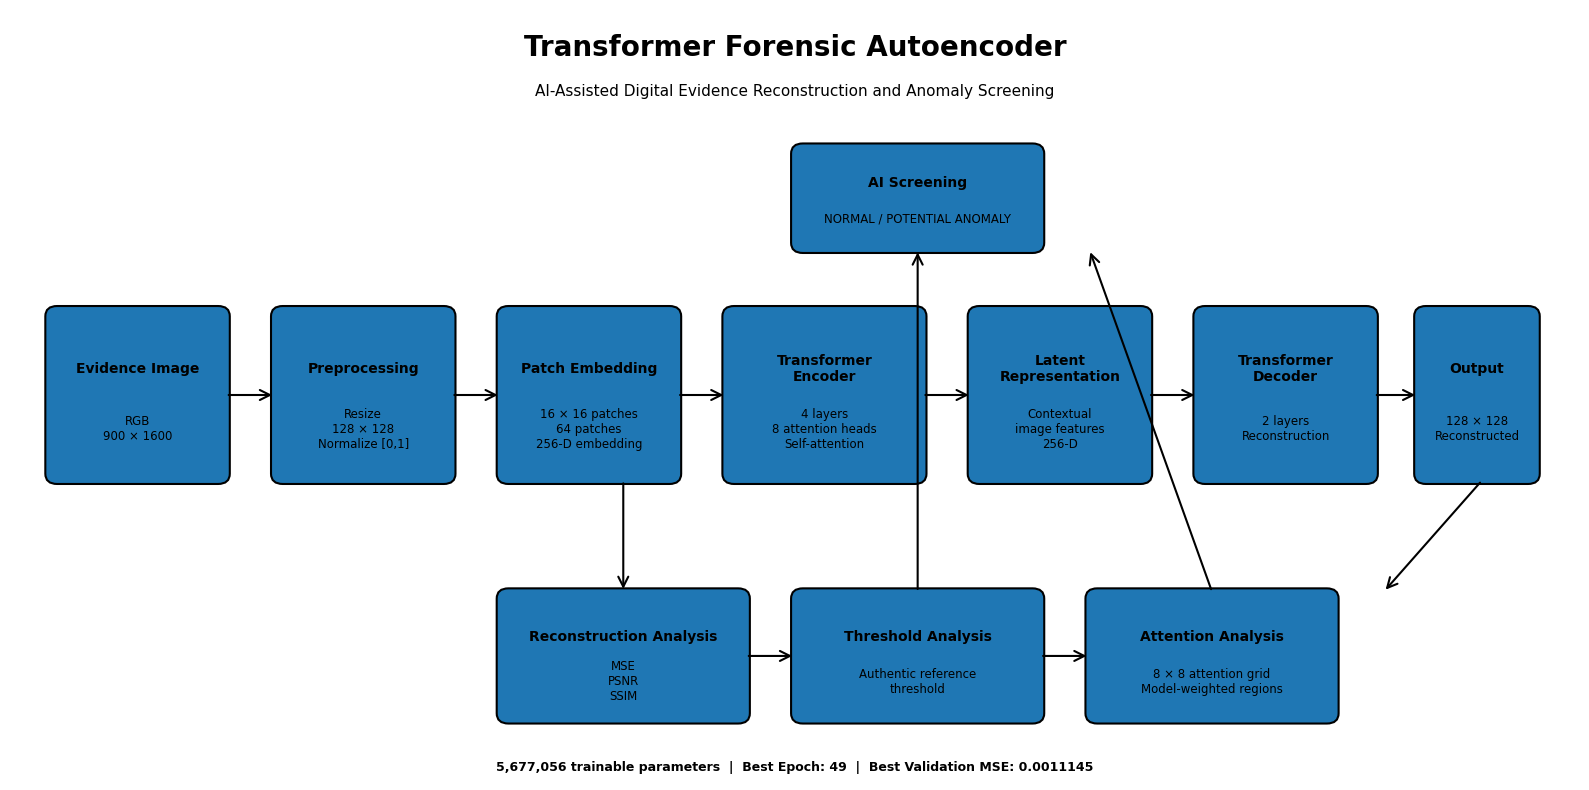


✅ MODEL ARCHITECTURE VISUALIZATION CREATED
Saved: /content/Transformer_Forensic_Autoencoder_Architecture.png
Input: 128 × 128 RGB
Patches: 64 × 16 × 16
Embedding: 256
Attention Heads: 8
Encoder Layers: 4
Decoder Layers: 2
Parameters: 5,677,056


In [46]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 8))

ax.set_xlim(0, 16)
ax.set_ylim(0, 9)
ax.axis("off")

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def add_box(x, y, w, h, title, details, fontsize=10):
    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x + w/2,
        y + h*0.65,
        title,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold"
    )

    ax.text(
        x + w/2,
        y + h*0.30,
        details,
        ha="center",
        va="center",
        fontsize=8.5
    )


def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=1.5
    )
    ax.add_patch(arrow)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.text(
    8,
    8.55,
    "Transformer Forensic Autoencoder",
    ha="center",
    va="center",
    fontsize=20,
    fontweight="bold"
)

ax.text(
    8,
    8.05,
    "AI-Assisted Digital Evidence Reconstruction and Anomaly Screening",
    ha="center",
    va="center",
    fontsize=11
)

# ------------------------------------------------------------
# Architecture boxes
# ------------------------------------------------------------

add_box(
    0.4, 3.5, 1.8, 2.0,
    "Evidence Image",
    "RGB\n900 × 1600"
)

add_box(
    2.7, 3.5, 1.8, 2.0,
    "Preprocessing",
    "Resize\n128 × 128\nNormalize [0,1]"
)

add_box(
    5.0, 3.5, 1.8, 2.0,
    "Patch Embedding",
    "16 × 16 patches\n64 patches\n256-D embedding"
)

add_box(
    7.3, 3.5, 2.0, 2.0,
    "Transformer\nEncoder",
    "4 layers\n8 attention heads\nSelf-attention"
)

add_box(
    9.8, 3.5, 1.8, 2.0,
    "Latent\nRepresentation",
    "Contextual\nimage features\n256-D"
)

add_box(
    12.1, 3.5, 1.8, 2.0,
    "Transformer\nDecoder",
    "2 layers\nReconstruction"
)

add_box(
    14.35, 3.5, 1.2, 2.0,
    "Output",
    "128 × 128\nReconstructed"
)

# ------------------------------------------------------------
# Arrows
# ------------------------------------------------------------

add_arrow(2.2, 4.5, 2.7, 4.5)
add_arrow(4.5, 4.5, 5.0, 4.5)
add_arrow(6.8, 4.5, 7.3, 4.5)
add_arrow(9.3, 4.5, 9.8, 4.5)
add_arrow(11.6, 4.5, 12.1, 4.5)
add_arrow(13.9, 4.5, 14.35, 4.5)

# ------------------------------------------------------------
# Analysis branch
# ------------------------------------------------------------

add_box(
    5.0, 0.7, 2.5, 1.5,
    "Reconstruction Analysis",
    "MSE\nPSNR\nSSIM"
)

add_box(
    8.0, 0.7, 2.5, 1.5,
    "Threshold Analysis",
    "Authentic reference\nthreshold"
)

add_box(
    11.0, 0.7, 2.5, 1.5,
    "Attention Analysis",
    "8 × 8 attention grid\nModel-weighted regions"
)

add_box(
    8.0, 6.2, 2.5, 1.2,
    "AI Screening",
    "NORMAL / POTENTIAL ANOMALY"
)

# Analysis arrows
add_arrow(15.0, 3.5, 14.0, 2.2)
add_arrow(6.25, 3.5, 6.25, 2.2)
add_arrow(7.5, 1.45, 8.0, 1.45)
add_arrow(10.5, 1.45, 11.0, 1.45)

# Threshold to screening
add_arrow(9.25, 2.2, 9.25, 6.2)

# Attention to screening
add_arrow(12.25, 2.2, 11.0, 6.2)

# ------------------------------------------------------------
# Model summary
# ------------------------------------------------------------

ax.text(
    8,
    0.15,
    "5,677,056 trainable parameters  |  Best Epoch: 49  |  "
    "Best Validation MSE: 0.0011145",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

MODEL_DIAGRAM = "/content/Transformer_Forensic_Autoencoder_Architecture.png"

plt.savefig(
    MODEL_DIAGRAM,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 65)
print("✅ MODEL ARCHITECTURE VISUALIZATION CREATED")
print("=" * 65)
print("Saved:", MODEL_DIAGRAM)
print("Input: 128 × 128 RGB")
print("Patches: 64 × 16 × 16")
print("Embedding: 256")
print("Attention Heads: 8")
print("Encoder Layers: 4")
print("Decoder Layers: 2")
print("Parameters: 5,677,056")
print("=" * 65)

# STEP 28 — TRANSFORMER MODEL: COMPLETE EVALUATION DASHBOARD

TRANSFORMER FORENSIC AUTOENCODER — EVALUATION

Available columns:
['path', 'label', 'class', 'mse', 'psnr', 'ssim']

Detected columns:
MSE   : mse
Label : label
PSNR  : psnr
SSIM  : ssim

RECONSTRUCTION RESULTS
Authentic images : 1498
Tampered images  : 1025

Authentic mean MSE : 0.001043
Tampered mean MSE  : 0.001186

Threshold          : 0.002253

CLASSIFICATION METRICS
Accuracy           : 0.5981
Precision          : 0.5364
Recall             : 0.0790
F1 Score           : 0.1378
Balanced Accuracy  : 0.5161
ROC-AUC            : 0.5460

Confusion Matrix:
TN = 1428
FP = 70
FN = 944
TP = 81


/tmp/ipykernel_1309/3567791396.py:569: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


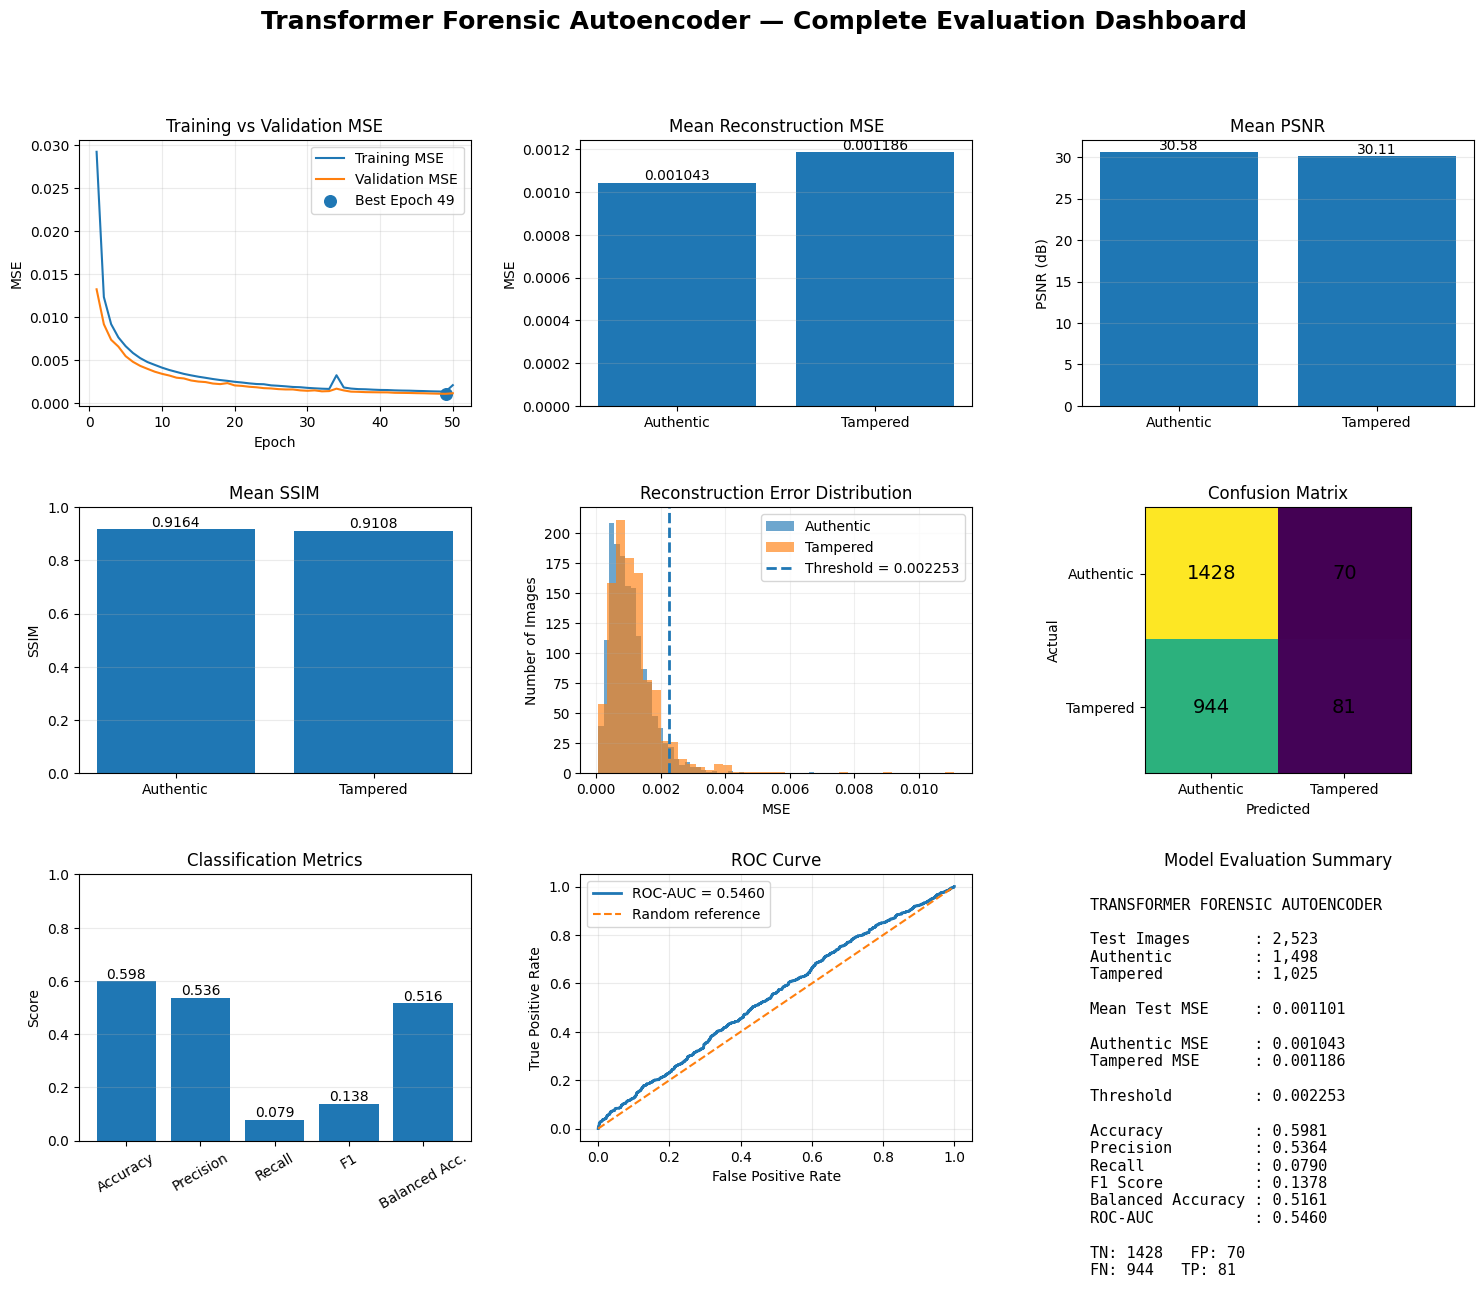


✅ COMPLETE EVALUATION DASHBOARD CREATED
Saved: /content/Transformer_Complete_Evaluation_Dashboard.png


In [47]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve
)

# ------------------------------------------------------------
# 1. Load per-image test results
# ------------------------------------------------------------

RESULTS_PATH = "/content/transformer_test_results.csv"

if not os.path.exists(RESULTS_PATH):
    raise FileNotFoundError(
        f"Test results file not found: {RESULTS_PATH}"
    )

df = pd.read_csv(RESULTS_PATH)

print("=" * 70)
print("TRANSFORMER FORENSIC AUTOENCODER — EVALUATION")
print("=" * 70)

print("\nAvailable columns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. Automatically identify important columns
# ------------------------------------------------------------

def find_column(columns, candidates):
    for candidate in candidates:
        for col in columns:
            if candidate.lower() == col.lower():
                return col

    for candidate in candidates:
        for col in columns:
            if candidate.lower() in col.lower():
                return col

    return None


mse_col = find_column(
    df.columns,
    ["mse", "reconstruction_mse", "reconstruction error"]
)

label_col = find_column(
    df.columns,
    ["label", "class", "target", "is_tampered", "ground_truth"]
)

psnr_col = find_column(
    df.columns,
    ["psnr", "psnr_db"]
)

ssim_col = find_column(
    df.columns,
    ["ssim"]
)


print("\nDetected columns:")
print("MSE   :", mse_col)
print("Label :", label_col)
print("PSNR  :", psnr_col)
print("SSIM  :", ssim_col)


if mse_col is None or label_col is None:
    raise ValueError(
        "Could not identify MSE and label columns. "
        "Please check the column names printed above."
    )


# ------------------------------------------------------------
# 3. Convert labels to binary
#    0 = Authentic
#    1 = Tampered
# ------------------------------------------------------------

def convert_label(x):

    if isinstance(x, str):
        s = x.strip().lower()

        if s in ["tampered", "tp", "1", "true", "fake"]:
            return 1

        if s in ["authentic", "au", "0", "false", "real"]:
            return 0

    try:
        return int(x)
    except:
        return np.nan


df["binary_label"] = df[label_col].apply(convert_label)

df = df.dropna(subset=[mse_col, "binary_label"]).copy()

df["binary_label"] = df["binary_label"].astype(int)

mse = df[mse_col].astype(float).values
y_true = df["binary_label"].values


# ------------------------------------------------------------
# 4. Authentic reference threshold
# ------------------------------------------------------------

THRESHOLD = 0.002252985490486025

y_pred = (mse > THRESHOLD).astype(int)


# ------------------------------------------------------------
# 5. Classification metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
balanced_acc = balanced_accuracy_score(y_true, y_pred)

roc_auc = roc_auc_score(y_true, mse)

cm = confusion_matrix(y_true, y_pred)

TN, FP, FN, TP = cm.ravel()


# ------------------------------------------------------------
# 6. Class-wise reconstruction metrics
# ------------------------------------------------------------

auth = df[df["binary_label"] == 0]
tampered = df[df["binary_label"] == 1]

auth_mse = auth[mse_col].mean()
tampered_mse = tampered[mse_col].mean()

print("\n" + "=" * 70)
print("RECONSTRUCTION RESULTS")
print("=" * 70)

print(f"Authentic images : {len(auth)}")
print(f"Tampered images  : {len(tampered)}")

print(f"\nAuthentic mean MSE : {auth_mse:.6f}")
print(f"Tampered mean MSE  : {tampered_mse:.6f}")

print(f"\nThreshold          : {THRESHOLD:.6f}")

print("\n" + "=" * 70)
print("CLASSIFICATION METRICS")
print("=" * 70)

print(f"Accuracy           : {accuracy:.4f}")
print(f"Precision          : {precision:.4f}")
print(f"Recall             : {recall:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"Balanced Accuracy  : {balanced_acc:.4f}")
print(f"ROC-AUC            : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(f"TN = {TN}")
print(f"FP = {FP}")
print(f"FN = {FN}")
print(f"TP = {TP}")


# ============================================================
# 7. COMPLETE VISUALIZATION DASHBOARD
# ============================================================

fig = plt.figure(figsize=(18, 13))

gs = fig.add_gridspec(
    3, 3,
    hspace=0.38,
    wspace=0.28
)


# ------------------------------------------------------------
# Plot 1 — Training / Validation MSE
# ------------------------------------------------------------

ax1 = fig.add_subplot(gs[0, 0])

# Try to find training history variables
train_history = None
val_history = None

possible_train_names = [
    "train_losses",
    "train_loss_history",
    "train_mse_history",
    "train_history"
]

possible_val_names = [
    "val_losses",
    "val_loss_history",
    "val_mse_history",
    "val_history"
]

for name in possible_train_names:
    if name in globals():
        train_history = globals()[name]
        break

for name in possible_val_names:
    if name in globals():
        val_history = globals()[name]
        break

if train_history is not None and val_history is not None:

    train_history = np.asarray(train_history, dtype=float)
    val_history = np.asarray(val_history, dtype=float)

    epochs = np.arange(1, len(train_history) + 1)

    ax1.plot(epochs, train_history, label="Training MSE")
    ax1.plot(epochs, val_history, label="Validation MSE")

    best_idx = np.argmin(val_history)

    ax1.scatter(
        epochs[best_idx],
        val_history[best_idx],
        s=70,
        label=f"Best Epoch {epochs[best_idx]}"
    )

    ax1.set_title("Training vs Validation MSE")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("MSE")
    ax1.legend()
    ax1.grid(alpha=0.25)

else:

    ax1.text(
        0.5, 0.5,
        "Training history variables\nnot found in memory",
        ha="center",
        va="center",
        fontsize=12
    )

    ax1.set_title("Training vs Validation MSE")


# ------------------------------------------------------------
# Plot 2 — Mean MSE by class
# ------------------------------------------------------------

ax2 = fig.add_subplot(gs[0, 1])

classes = ["Authentic", "Tampered"]
mse_values = [auth_mse, tampered_mse]

bars = ax2.bar(classes, mse_values)

ax2.set_title("Mean Reconstruction MSE")
ax2.set_ylabel("MSE")
ax2.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, mse_values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.6f}",
        ha="center",
        va="bottom"
    )


# ------------------------------------------------------------
# Plot 3 — PSNR by class
# ------------------------------------------------------------

ax3 = fig.add_subplot(gs[0, 2])

if psnr_col is not None:

    auth_psnr = auth[psnr_col].mean()
    tampered_psnr = tampered[psnr_col].mean()

    values = [auth_psnr, tampered_psnr]

    bars = ax3.bar(classes, values)

    ax3.set_title("Mean PSNR")
    ax3.set_ylabel("PSNR (dB)")
    ax3.grid(axis="y", alpha=0.25)

    for bar, value in zip(bars, values):
        ax3.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom"
        )

else:

    ax3.text(
        0.5, 0.5,
        "PSNR data not available",
        ha="center",
        va="center"
    )

    ax3.set_title("Mean PSNR")


# ------------------------------------------------------------
# Plot 4 — SSIM by class
# ------------------------------------------------------------

ax4 = fig.add_subplot(gs[1, 0])

if ssim_col is not None:

    auth_ssim = auth[ssim_col].mean()
    tampered_ssim = tampered[ssim_col].mean()

    values = [auth_ssim, tampered_ssim]

    bars = ax4.bar(classes, values)

    ax4.set_title("Mean SSIM")
    ax4.set_ylabel("SSIM")
    ax4.set_ylim(0, 1)
    ax4.grid(axis="y", alpha=0.25)

    for bar, value in zip(bars, values):
        ax4.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

else:

    ax4.text(
        0.5, 0.5,
        "SSIM data not available",
        ha="center",
        va="center"
    )

    ax4.set_title("Mean SSIM")


# ------------------------------------------------------------
# Plot 5 — Reconstruction error distribution
# ------------------------------------------------------------

ax5 = fig.add_subplot(gs[1, 1])

ax5.hist(
    auth[mse_col],
    bins=40,
    alpha=0.65,
    label="Authentic"
)

ax5.hist(
    tampered[mse_col],
    bins=40,
    alpha=0.65,
    label="Tampered"
)

ax5.axvline(
    THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD:.6f}"
)

ax5.set_title("Reconstruction Error Distribution")
ax5.set_xlabel("MSE")
ax5.set_ylabel("Number of Images")
ax5.legend()
ax5.grid(alpha=0.2)


# ------------------------------------------------------------
# Plot 6 — Confusion Matrix
# ------------------------------------------------------------

ax6 = fig.add_subplot(gs[1, 2])

im = ax6.imshow(cm)

ax6.set_title("Confusion Matrix")
ax6.set_xlabel("Predicted")
ax6.set_ylabel("Actual")

ax6.set_xticks([0, 1])
ax6.set_yticks([0, 1])

ax6.set_xticklabels(["Authentic", "Tampered"])
ax6.set_yticklabels(["Authentic", "Tampered"])

for i in range(2):
    for j in range(2):
        ax6.text(
            j, i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14
        )


# ------------------------------------------------------------
# Plot 7 — Evaluation Metrics
# ------------------------------------------------------------

ax7 = fig.add_subplot(gs[2, 0])

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced Acc."
]

metric_values = [
    accuracy,
    precision,
    recall,
    f1,
    balanced_acc
]

bars = ax7.bar(metric_names, metric_values)

ax7.set_title("Classification Metrics")
ax7.set_ylabel("Score")
ax7.set_ylim(0, 1)
ax7.tick_params(axis="x", rotation=30)
ax7.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, metric_values):
    ax7.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )


# ------------------------------------------------------------
# Plot 8 — ROC Curve
# ------------------------------------------------------------

ax8 = fig.add_subplot(gs[2, 1])

fpr, tpr, _ = roc_curve(y_true, mse)

ax8.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

ax8.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random reference"
)

ax8.set_title("ROC Curve")
ax8.set_xlabel("False Positive Rate")
ax8.set_ylabel("True Positive Rate")
ax8.legend()
ax8.grid(alpha=0.25)


# ------------------------------------------------------------
# Plot 9 — Overall Model Summary
# ------------------------------------------------------------

ax9 = fig.add_subplot(gs[2, 2])

ax9.axis("off")

summary_text = f"""
TRANSFORMER FORENSIC AUTOENCODER

Test Images       : {len(df):,}
Authentic         : {len(auth):,}
Tampered          : {len(tampered):,}

Mean Test MSE     : {mse.mean():.6f}

Authentic MSE     : {auth_mse:.6f}
Tampered MSE      : {tampered_mse:.6f}

Threshold         : {THRESHOLD:.6f}

Accuracy          : {accuracy:.4f}
Precision         : {precision:.4f}
Recall            : {recall:.4f}
F1 Score          : {f1:.4f}
Balanced Accuracy : {balanced_acc:.4f}
ROC-AUC           : {roc_auc:.4f}

TN: {TN}   FP: {FP}
FN: {FN}   TP: {TP}
"""

ax9.text(
    0.02,
    0.98,
    summary_text,
    transform=ax9.transAxes,
    va="top",
    fontsize=11,
    family="monospace"
)

ax9.set_title("Model Evaluation Summary")


# ------------------------------------------------------------
# Main dashboard title
# ------------------------------------------------------------

fig.suptitle(
    "Transformer Forensic Autoencoder — Complete Evaluation Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])


# ------------------------------------------------------------
# Save dashboard
# ------------------------------------------------------------

dashboard_path = "/content/Transformer_Complete_Evaluation_Dashboard.png"

plt.savefig(
    dashboard_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("✅ COMPLETE EVALUATION DASHBOARD CREATED")
print("=" * 70)
print("Saved:", dashboard_path)

# STEP 29 — PPT-READY TRANSFORMER EVALUATION RESULTS


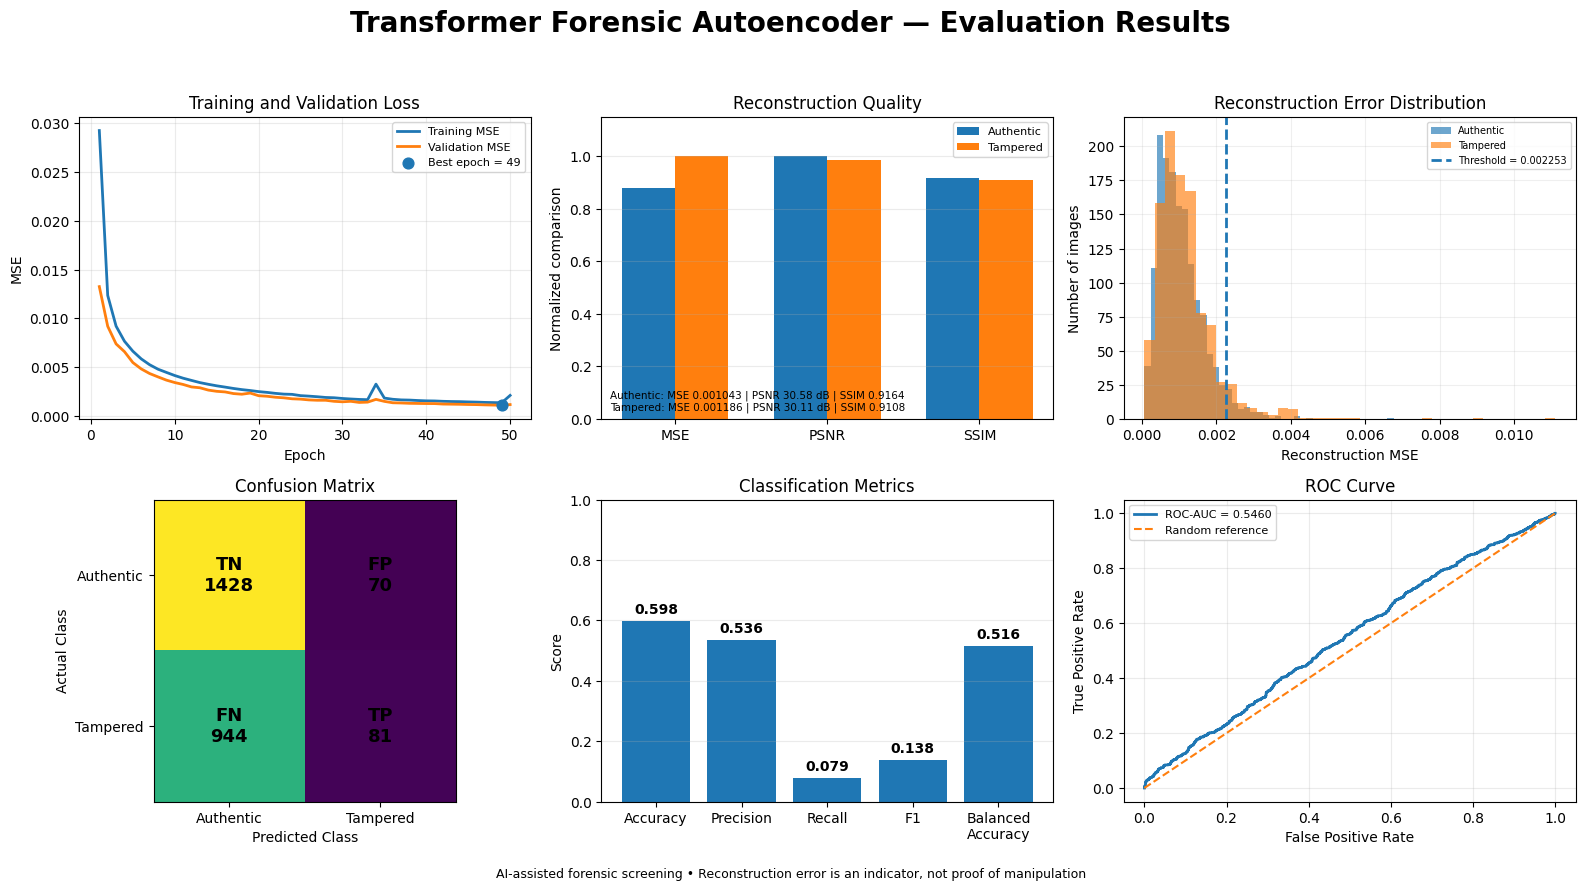

✅ STEP 29 COMPLETE — PPT-READY EVALUATION FIGURE
Saved to: /content/Transformer_PPT_Evaluation_Results.png

Key results:
Accuracy          : 0.5981
Precision         : 0.5364
Recall            : 0.0790
F1 Score          : 0.1378
Balanced Accuracy : 0.5161
ROC-AUC           : 0.5460
Threshold         : 0.002253


In [48]:


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# Load test results
# ------------------------------------------------------------

RESULTS_PATH = "/content/transformer_test_results.csv"

df = pd.read_csv(RESULTS_PATH)

# Detect columns
def get_col(candidates):
    for c in candidates:
        for actual in df.columns:
            if actual.lower() == c.lower():
                return actual
    for c in candidates:
        for actual in df.columns:
            if c.lower() in actual.lower():
                return actual
    return None

mse_col = get_col(["mse", "reconstruction_mse"])
label_col = get_col(["label", "class", "target"])
psnr_col = get_col(["psnr", "psnr_db"])
ssim_col = get_col(["ssim"])

# ------------------------------------------------------------
# Convert labels
# 0 = Authentic
# 1 = Tampered
# ------------------------------------------------------------

def to_binary(x):
    if isinstance(x, str):
        x = x.lower().strip()

        if x in ["tampered", "tp", "1", "fake"]:
            return 1
        if x in ["authentic", "au", "0", "real"]:
            return 0

    return int(x)

df["binary_label"] = df[label_col].apply(to_binary)

mse = df[mse_col].astype(float).values
y_true = df["binary_label"].values

auth = df[df["binary_label"] == 0]
tampered = df[df["binary_label"] == 1]

# ------------------------------------------------------------
# Fixed authentic-reference threshold
# ------------------------------------------------------------

THRESHOLD = 0.002252985490486025

y_pred = (mse > THRESHOLD).astype(int)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, mse)

cm = confusion_matrix(y_true, y_pred)
TN, FP, FN, TP = cm.ravel()

# ------------------------------------------------------------
# Class-wise reconstruction metrics
# ------------------------------------------------------------

auth_mse = auth[mse_col].mean()
tampered_mse = tampered[mse_col].mean()

auth_psnr = auth[psnr_col].mean() if psnr_col else None
tampered_psnr = tampered[psnr_col].mean() if psnr_col else None

auth_ssim = auth[ssim_col].mean() if ssim_col else None
tampered_ssim = tampered[ssim_col].mean() if ssim_col else None

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

train_hist = None
val_hist = None

for name in [
    "train_losses",
    "train_loss_history",
    "train_mse_history",
    "train_history"
]:
    if name in globals():
        train_hist = np.asarray(globals()[name], dtype=float)
        break

for name in [
    "val_losses",
    "val_loss_history",
    "val_mse_history",
    "val_history"
]:
    if name in globals():
        val_hist = np.asarray(globals()[name], dtype=float)
        break

# ============================================================
# CREATE CLEAN PPT FIGURE
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

fig.suptitle(
    "Transformer Forensic Autoencoder — Evaluation Results",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ------------------------------------------------------------
# 1. Training and validation
# ------------------------------------------------------------

ax = axes[0, 0]

if train_hist is not None and val_hist is not None:

    epochs = np.arange(1, len(train_hist) + 1)

    ax.plot(
        epochs,
        train_hist,
        linewidth=2,
        label="Training MSE"
    )

    ax.plot(
        epochs,
        val_hist,
        linewidth=2,
        label="Validation MSE"
    )

    best_epoch = np.argmin(val_hist) + 1
    best_value = np.min(val_hist)

    ax.scatter(
        best_epoch,
        best_value,
        s=60,
        zorder=5,
        label=f"Best epoch = {best_epoch}"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_title("Training and Validation Loss")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

else:

    ax.text(
        0.5, 0.5,
        "Training history unavailable",
        ha="center",
        va="center"
    )

    ax.set_title("Training and Validation Loss")


# ------------------------------------------------------------
# 2. Reconstruction quality
# ------------------------------------------------------------

ax = axes[0, 1]

metrics = ["MSE", "PSNR", "SSIM"]

# Normalize values only for visual comparison
# Actual values are printed above bars.

metric_positions = np.arange(3)

auth_norm = [
    auth_mse / max(auth_mse, tampered_mse),
    auth_psnr / max(auth_psnr, tampered_psnr),
    auth_ssim
]

tampered_norm = [
    tampered_mse / max(auth_mse, tampered_mse),
    tampered_psnr / max(auth_psnr, tampered_psnr),
    tampered_ssim
]

width = 0.35

ax.bar(
    metric_positions - width / 2,
    auth_norm,
    width,
    label="Authentic"
)

ax.bar(
    metric_positions + width / 2,
    tampered_norm,
    width,
    label="Tampered"
)

ax.set_xticks(metric_positions)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)

ax.set_ylabel("Normalized comparison")
ax.set_title("Reconstruction Quality")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.25)

# Actual values as text
ax.text(
    0.02, 0.02,
    f"Authentic: MSE {auth_mse:.6f} | "
    f"PSNR {auth_psnr:.2f} dB | SSIM {auth_ssim:.4f}\n"
    f"Tampered: MSE {tampered_mse:.6f} | "
    f"PSNR {tampered_psnr:.2f} dB | SSIM {tampered_ssim:.4f}",
    transform=ax.transAxes,
    fontsize=7.5,
    va="bottom"
)


# ------------------------------------------------------------
# 3. Reconstruction error distribution
# ------------------------------------------------------------

ax = axes[0, 2]

ax.hist(
    auth[mse_col],
    bins=40,
    alpha=0.65,
    label="Authentic"
)

ax.hist(
    tampered[mse_col],
    bins=40,
    alpha=0.65,
    label="Tampered"
)

ax.axvline(
    THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD:.6f}"
)

ax.set_xlabel("Reconstruction MSE")
ax.set_ylabel("Number of images")
ax.set_title("Reconstruction Error Distribution")
ax.legend(fontsize=7)
ax.grid(alpha=0.2)


# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------

ax = axes[1, 0]

ax.imshow(cm)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Authentic", "Tampered"])
ax.set_yticklabels(["Authentic", "Tampered"])

for i in range(2):
    for j in range(2):

        label = ""

        if i == 0 and j == 0:
            label = f"TN\n{cm[i,j]}"
        elif i == 0 and j == 1:
            label = f"FP\n{cm[i,j]}"
        elif i == 1 and j == 0:
            label = f"FN\n{cm[i,j]}"
        else:
            label = f"TP\n{cm[i,j]}"

        ax.text(
            j,
            i,
            label,
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold"
        )


# ------------------------------------------------------------
# 5. Classification metrics
# ------------------------------------------------------------

ax = axes[1, 1]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced\nAccuracy"
]

metric_values = [
    accuracy,
    precision,
    recall,
    f1,
    balanced_acc
]

bars = ax.bar(
    metric_names,
    metric_values
)

ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Classification Metrics")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, metric_values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.025,
        f"{value:.3f}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )


# ------------------------------------------------------------
# 6. ROC curve
# ------------------------------------------------------------

ax = axes[1, 2]

fpr, tpr, _ = roc_curve(y_true, mse)

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random reference"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)


# ============================================================
# FOOTER
# ============================================================

fig.text(
    0.5,
    0.015,
    "AI-assisted forensic screening • Reconstruction error is an indicator, not proof of manipulation",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.035, 1, 0.95]
)

# ------------------------------------------------------------
# Save high-resolution PPT image
# ------------------------------------------------------------

PPT_RESULT_PATH = (
    "/content/Transformer_PPT_Evaluation_Results.png"
)

plt.savefig(
    PPT_RESULT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("✅ STEP 29 COMPLETE — PPT-READY EVALUATION FIGURE")
print("=" * 70)

print(f"Saved to: {PPT_RESULT_PATH}")

print("\nKey results:")
print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"Balanced Accuracy : {balanced_acc:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")
print(f"Threshold         : {THRESHOLD:.6f}")

# STEP 30 — TRANSFORMER MODEL SUMMARY & PARAMETER BREAKDOWN


TRANSFORMER FORENSIC AUTOENCODER — MODEL SUMMARY
Device                 : cuda
Total parameters       : 5,677,056
Trainable parameters   : 5,677,056
Non-trainable params   : 0

PARAMETER BREAKDOWN
          Component  Parameters  Trainable
        patch_embed      196864     196864
            encoder     3159040    3159040
        latent_norm         512        512
            decoder     2106880    2106880
reconstruction_head      197376     197376

ARCHITECTURE CONFIGURATION

Input
  └── RGB image: 128 × 128

Patch Embedding
  ├── Patch size: 16 × 16
  ├── Number of patches: 64
  └── Embedding dimension: 256

Transformer Encoder
  ├── Encoder layers: 4
  ├── Attention heads: 8
  ├── Self-attention
  └── Contextual feature learning

Latent Representation
  └── Global latent representation: 256-D

Transformer Decoder
  ├── Decoder layers: 2
  └── Reconstruction from latent tokens

Output
  └── Reconstructed image: 128 × 128 RGB



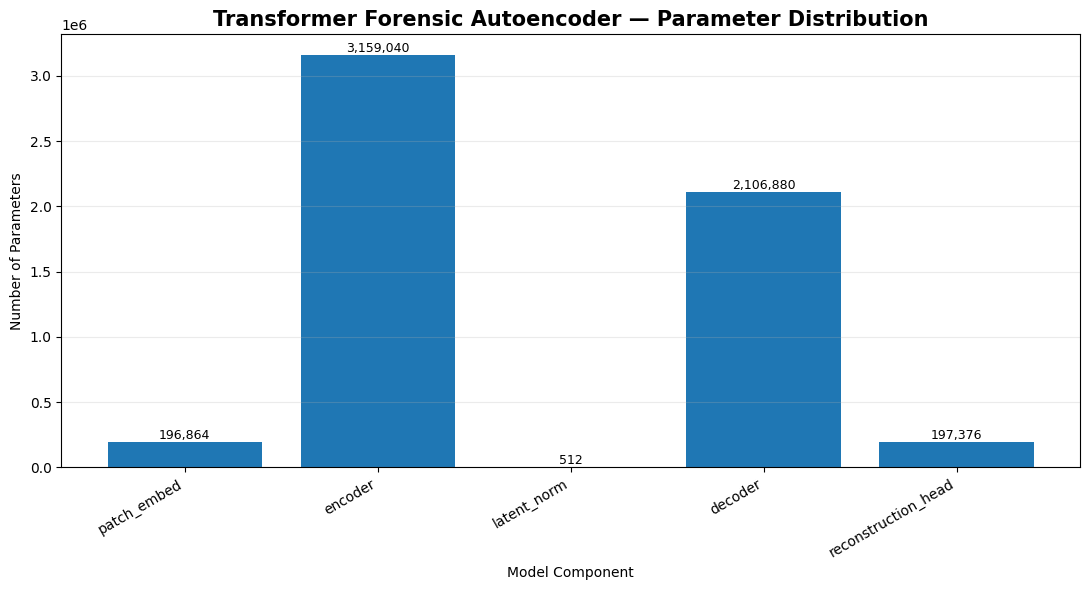


✅ STEP 30 COMPLETE
Total parameters     : 5,677,056
Trainable parameters : 5,677,056

Files created:
Parameter chart : /content/Transformer_Parameter_Distribution.png
Parameter CSV   : /content/Transformer_Parameter_Breakdown.csv

Model:
Transformer Forensic Autoencoder
Input: 128 × 128 RGB
Patches: 64
Embedding: 256
Attention heads: 8
Encoder layers: 4
Decoder layers: 2


In [49]:

import torch
import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. Load best trained model
# ------------------------------------------------------------

CHECKPOINT_PATH = (
    "/content/transformer_checkpoints/"
    "best_transformer_forensic.pth"
)

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}"
    )

# Make sure model exists
model = model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

# Handle both possible checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

# ------------------------------------------------------------
# 3. Count parameters
# ------------------------------------------------------------

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = total_params - trainable_params

print("=" * 75)
print("TRANSFORMER FORENSIC AUTOENCODER — MODEL SUMMARY")
print("=" * 75)

print(f"Device                 : {device}")
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")


# ============================================================
# 4. Layer-wise parameter breakdown
# ============================================================

rows = []

for name, module in model.named_children():

    params = sum(
        p.numel()
        for p in module.parameters()
    )

    trainable = sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

    rows.append({
        "Component": name,
        "Parameters": params,
        "Trainable": trainable
    })

param_df = pd.DataFrame(rows)

print("\n" + "=" * 75)
print("PARAMETER BREAKDOWN")
print("=" * 75)

print(param_df.to_string(index=False))


# ============================================================
# 5. Detailed architecture information
# ============================================================

print("\n" + "=" * 75)
print("ARCHITECTURE CONFIGURATION")
print("=" * 75)

print("""
Input
  └── RGB image: 128 × 128

Patch Embedding
  ├── Patch size: 16 × 16
  ├── Number of patches: 64
  └── Embedding dimension: 256

Transformer Encoder
  ├── Encoder layers: 4
  ├── Attention heads: 8
  ├── Self-attention
  └── Contextual feature learning

Latent Representation
  └── Global latent representation: 256-D

Transformer Decoder
  ├── Decoder layers: 2
  └── Reconstruction from latent tokens

Output
  └── Reconstructed image: 128 × 128 RGB
""")


# ============================================================
# 6. Model parameter chart
# ============================================================

plt.figure(figsize=(11, 6))

components = param_df["Component"].tolist()
values = param_df["Parameters"].tolist()

bars = plt.bar(
    components,
    values
)

plt.title(
    "Transformer Forensic Autoencoder — Parameter Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model Component")
plt.ylabel("Number of Parameters")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(bars, values):

    if value > 0:

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:,}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()

PARAM_CHART = (
    "/content/Transformer_Parameter_Distribution.png"
)

plt.savefig(
    PARAM_CHART,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. Save parameter table
# ============================================================

PARAM_CSV = (
    "/content/Transformer_Parameter_Breakdown.csv"
)

param_df.to_csv(
    PARAM_CSV,
    index=False
)


# ============================================================
# 8. Final summary
# ============================================================

print("\n" + "=" * 75)
print("✅ STEP 30 COMPLETE")
print("=" * 75)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print("\nFiles created:")
print(f"Parameter chart : {PARAM_CHART}")
print(f"Parameter CSV   : {PARAM_CSV}")

print("\nModel:")
print("Transformer Forensic Autoencoder")
print("Input: 128 × 128 RGB")
print("Patches: 64")
print("Embedding: 256")
print("Attention heads: 8")
print("Encoder layers: 4")
print("Decoder layers: 2")